In [15]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# HD 35929 — Grid figures (no merit function)
**Figures notebook:** HRDs, box checks and other figures made straight from the parquet files. Nothing here uses MD or chi2 results.

Companions: `mode_matching_main.ipynb` (merit functions, corner plots, everything that uses their results), `mode_matching_tests.ipynb` (seismic-only curiosity check and other tests on the parquet files), `mode_matching_figures.ipynb` (HRDs, box checks and other grid figures).

*Sections 1–2 (configuration, data loaders, observables, candidate builders, model filters) are **identical** in all three notebooks. If you change a setting here, copy it to the other two.*

## 1. Configuration

In [16]:
import sys
import numpy as np
import pandas as pd
import hd35929_matching as hd
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.colors import Normalize
from matplotlib.patches import Rectangle
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from matplotlib.gridspec import GridSpec
import matplotlib.transforms as mtransforms

import pyarrow.compute as pc
import pyarrow.parquet as pq

 
FOAM_PATH = r"C:\Users\Kian\Desktop\Uni\KU Leuven\ConnyProj\Pipelines+Data\ForwardModelling\FOAM"
sys.path.insert(0, FOAM_PATH)
from foam import maximum_likelihood_estimator as mle

MACHINE = "windows"

_FM_WINDOWS = Path(r"C:\Users\Kian\Desktop\Uni\KU Leuven\ConnyProj"
                   r"\Pipelines+Data\ForwardModelling")
_ROOTS = {
    "windows": dict(
        parquet=_FM_WINDOWS / "Grids_Parquet",
        p_file=Path(r"C:\Users\Kian\Desktop\Uni\KU Leuven\ConnyProj"
                    r"\Pipelines+Data\FrequencyAnalysis\pmode_Run_2_+_Run_3_final.csv"),
        gyre_detail=_FM_WINDOWS,
        storm_eigen=_FM_WINDOWS,
        ster=Path(r"C:\Users\Kian\Desktop\Uni\KU Leuven\ConnyProj\STER\HD35929"),
    ),
    "ster": dict(
        parquet=Path("/STER/kianTedeskino/HD35929/Grids_Parquet"),                    # check
        p_file=Path("/home/r1082832/ConnyProj/Analysis/Frequency_analysis"
                    "/analysis_output/pmode_Run_2_+_Run_3_final.csv"),
        gyre_detail=Path("/STER/kianTedeskino/HD35929/gyre_grid/gyre_best_rerun"),
        storm_eigen=Path("/STER/kianTedeskino/HD35929/storm_grid/best_eigenfunctions"),
        ster=Path("/STER/kianTedeskino/HD35929"),
    ),
}
ROOT = _ROOTS[MACHINE]

MODES_PARQUET       = ROOT["parquet"] / "modes.parquet"
MODELS_PARQUET      = ROOT["parquet"] / "models.parquet"
MODELS_ALL_PARQUET  = ROOT["parquet"] / "models_all.parquet"
INN_MODES_PARQUET   = ROOT["parquet"] / "innsbruck_modes.parquet"
INN_MODELS_PARQUET  = ROOT["parquet"] / "innsbruck_models.parquet"
STORM_MODES_PARQUET = ROOT["parquet"] / "storm_modes.parquet"

for _p in (MODES_PARQUET, MODELS_PARQUET, STORM_MODES_PARQUET, ROOT["p_file"],
           ROOT["gyre_detail"], ROOT["storm_eigen"]):
    if not _p.exists():
        print(f"WARNING ({MACHINE}): {_p} not found")

In [17]:
plt.rcParams.update({'font.family': 'serif',
                      'font.serif': ['cmr10'],          # Computer Modern Roman
                      'mathtext.fontset': 'cm',         # CM for math text
                      'axes.formatter.use_mathtext': True,
                      'xtick.direction': 'in',
                      'ytick.direction': 'in',
                    })

In [18]:
# ==========================================================================
# 1. CONFIG - all analysis choices
# ==========================================================================

# --- observed frequencies --------------------------------------------------
# Two separate lists. Set G_FILE = None (or point at an empty file) and the
# whole g-mode branch is skipped: no chi2 contribution, no merge, no cells
# to comment out.
P_FILE = str(ROOT["p_file"])
G_FILE = None

P_IDS = None        # None = use every row in the file; or e.g. ["F1","F2","F3"]
G_IDS = None

# Which error column to read. freq_err is the analytic estimate, freq_err_mc
# the Monte-Carlo one (~2x larger, and the more realistic of the two).
# Under the floor below the choice is numerically moot, but state it anyway.
ERR_COL = "freq_err_mc"

P_L = 2             # spherical degree assumed for the p-mode multiplet

FREQ_PAD = 5.0   # d^-1. Window half-width around the observed p-modes.
                 # Must exceed the full quintuplet span (4 x splitting
                 # ~ 2.5 d^-1): only 3 of 5 members are observed, so the
                 # multiplet centre can sit outside the observed range.

# --- rotation --------------------------------------------------------------
# Measured independently from the spectra, NOT taken from the p-mode list.
# Everything geometric below (sin i, v_eq, v/v_crit, the R box) depends on
# it, so it is set explicitly rather than inherited from a candidate file.
F_ROT_CPD     = 0.72832
F_ROT_ERR_CPD = 0.00050
F_ROT_BOX_FRAC = 0.20 

ASSIGNMENTS = [(-2, 0, 1), (-1, 1, 2)]

# --- spectroscopic + literature constraints (FILTERS, not chi2 terms) ------
TEFF_CENTRAL, TEFF_SIGMA = 7004.5, 226.5
TEFF_NSIGMA = 1.0                                       # try 2.0 and report the sensitivity
TEFF_BOX = (TEFF_CENTRAL - TEFF_NSIGMA * TEFF_SIGMA,
            TEFF_CENTRAL + TEFF_NSIGMA * TEFF_SIGMA)    # K


# From Casagrande tool we have:
# best fit:  E(B-V) = 0.1270   A_V = 0.394
#            logL   = 1.9522   L   = 89.6 Lsun

# Monte Carlo: 996/1000 converged
# quantity        median   -1 sigma   +1 sigma
# E(B-V)          0.1277     0.0460     0.0415
# A_V             0.3960     0.1427     0.1286
# logL            1.9537     0.0543     0.0470
# L [Lsun]       89.8779    10.5659    10.2710

# -> L_BOX for the mode matching: (68.7, 110.4) Lsun  [2 sigma]
L_CENTRAL, L_SIGMA = 89.9874, 10.5260  # 71.1666, 1.4752
L_NSIGMA = 1.0
L_BOX    = (L_CENTRAL - L_NSIGMA * L_SIGMA, 
            L_CENTRAL + L_NSIGMA * L_SIGMA)             # L_sun


VSINI_KMS      = 66.132
VSINI_ERR_KMS  = 3.485
INCL_VLTI_DEG  = 31.8
INCL_ERR_DEG   = 16.0


#-------STORM--------
FORCE_DIR   = "increasing"   # m rises with frequency (inertial frame)
F0_TOL      = 0.02           # |residual| of freq_0 about a line in m, / slope
SLOPE_RANGE = (0.78, 1.25)   

## 2. Data loaders

In [19]:
# ==========================================================================
# 2. LOAD Frequency dandidates
# ==========================================================================
p_obs = hd.load_candidates(P_FILE, ids=P_IDS, err_col=ERR_COL)
g_obs = hd.load_candidates(G_FILE, ids=G_IDS, err_col=ERR_COL)

print(f"p-modes ({len(p_obs)}):")
print(p_obs.to_string(index=False))
if len(p_obs) > 1:
    print(f"  spacings: {np.diff(p_obs['freq'].to_numpy()).round(5)} d^-1")
    d = np.diff(p_obs["freq"].to_numpy())
    if len(d) == 2:
        print(f"  spacing ratio: {d[0]/d[1]:.4f}  "
              "(2.0 => m = (-2, 0, +1) or mirror; 1.0 => (-1, 0, +1))")
print(f"\ng-modes ({len(g_obs)}): "
      f"{'none - g-mode branch skipped' if g_obs.empty else ''}")
if not g_obs.empty:
    print(g_obs.to_string(index=False))

print(f"\nf_rot (spectroscopic): {F_ROT_CPD:.6f} +/- {F_ROT_ERR_CPD:.6f} d^-1")
# The splitting coefficient is NOT computed here. A naive mean of the two
# spacings ignores the m^2 term and gives a third, wrong answer that differs
# from both estimators in the next cell at the 2e-4 d^-1 level. Cell 5 defines
# a_phys and a_fit; use those.

# Hard geometric floor on the radius: sin i <= 1 requires R >= vsini/(2 pi f).
R_floor = (VSINI_KMS * 1e3) / (2 * np.pi * F_ROT_CPD / 86400.0) / hd.R_SUN
print(f"\ngeometric floor from sin i <= 1: R >= {R_floor:.3f} R_sun")

p-modes (3):
ID      freq      err
F1 22.691107 0.000066
F2 23.960970 0.000059
F3 24.594737 0.000031
  spacings: [1.26986 0.63377] d^-1
  spacing ratio: 2.0037  (2.0 => m = (-2, 0, +1) or mirror; 1.0 => (-1, 0, +1))

g-modes (0): none - g-mode branch skipped

f_rot (spectroscopic): 0.728320 +/- 0.000500 d^-1

geometric floor from sin i <= 1: R >= 1.795 R_sun


## Omega crit calc

In [20]:
# ==========================================================================
# Expected Omega/Omega_crit from the observations alone (no models)
# ==========================================================================
# R range = intersection of the Stefan-Boltzmann range (L, Teff boxes) and the
# vsini + VLTI inclination range. M range = the grid's. Omega_crit is
# Keplerian, sqrt(GM/R^3); for rigid rotation this is also v_eq/v_crit.
M_RANGE = (1.8, 3.2)                                   # Msun

R_SB = (np.sqrt(L_BOX[0]) * (5772.0 / TEFF_BOX[1]) ** 2,
        np.sqrt(L_BOX[1]) * (5772.0 / TEFF_BOX[0]) ** 2)
_w = 2 * np.pi * F_ROT_CPD / 86400.0                   # rad/s
R_VS = ((VSINI_KMS - VSINI_ERR_KMS) * 1e3
        / (_w * np.sin(np.radians(INCL_VLTI_DEG + INCL_ERR_DEG))) / hd.R_SUN,
        (VSINI_KMS + VSINI_ERR_KMS) * 1e3
        / (_w * np.sin(np.radians(INCL_VLTI_DEG - INCL_ERR_DEG))) / hd.R_SUN)
R_OK = (max(R_SB[0], R_VS[0]), min(R_SB[1], R_VS[1]))
assert R_OK[0] < R_OK[1], "the two radius ranges do not overlap"

def om_ratio(M, R):
    """Omega_obs / Omega_Kepler for M [Msun], R [Rsun]."""
    return _w / np.sqrt(hd.G_SI * M * hd.M_SUN / (R * hd.R_SUN) ** 3)

lo = om_ratio(M_RANGE[1], R_OK[0])        # heaviest, most compact
hi = om_ratio(M_RANGE[0], R_OK[1])        # lightest, most extended
R_break = (hd.G_SI * np.array(M_RANGE) * hd.M_SUN / _w**2) ** (1/3) / hd.R_SUN

print(f"R from L, Teff (SB)  : {R_SB[0]:.2f} - {R_SB[1]:.2f} Rsun")
print(f"R from vsini, i      : {R_VS[0]:.2f} - {R_VS[1]:.2f} Rsun")
print(f"R combined           : {R_OK[0]:.2f} - {R_OK[1]:.2f} Rsun")
print(f"M (grid)             : {M_RANGE[0]} - {M_RANGE[1]} Msun")
print(f"v_eq at f_rot        : {_w*R_OK[0]*hd.R_SUN/1e3:.0f} - "
      f"{_w*R_OK[1]*hd.R_SUN/1e3:.0f} km/s")
print(f"Omega/Omega_crit     : {lo:.2f} - {hi:.2f}")
print(f"break-up radius at f_rot: {R_break[0]:.2f} Rsun (M={M_RANGE[0]}) "
      f"to {R_break[1]:.2f} Rsun (M={M_RANGE[1]})")

R from L, Teff (SB)  : 5.68 - 7.27 Rsun
R from vsini, i      : 2.30 - 6.94 Rsun
R combined           : 5.68 - 6.94 Rsun
M (grid)             : 1.8 - 3.2 Msun
v_eq at f_rot        : 209 - 256 km/s
Omega/Omega_crit     : 0.64 - 1.15
break-up radius at f_rot: 6.32 Rsun (M=1.8) to 7.66 Rsun (M=3.2)


### Own MESA Grid (PMS+MS)

In [21]:
modes = hd.load_modes(
    MODES_PARQUET, mode_type="p", l=P_L,
    freq_lo=p_obs["freq"].min() - FREQ_PAD,
    freq_hi=p_obs["freq"].max() + FREQ_PAD,
)
print(f"{len(modes):,} l={P_L} p-modes in window "
      f"[{p_obs['freq'].min()-FREQ_PAD:.2f}, "
      f"{p_obs['freq'].max()+FREQ_PAD:.2f}] d^-1")

761,416 l=2 p-modes in window [17.69, 29.59] d^-1


In [22]:
# ==========================================================================
# 2. LOAD MESA own grid
# ==========================================================================
# Models must be attached BEFORE the multiplet is built: the splitting
# needs each model's own Omega, which lives in models.parquet.
modes = hd.attach_models(modes, MODELS_PARQUET)
print(f"{len(modes):,} modes with MESA parameters attached")

# Which MESA models actually carry rotation in their structure? Rotation was
# injected at ZAMS, so this is False for the whole PMS branch - those models
# are non-rotating structures, as in the SpaceInn grid.
if "f_rot_model_cpd" not in modes.columns:
    modes["f_rot_model_cpd"] = np.nan
modes["rotating_structure"] = modes["f_rot_model_cpd"].fillna(0.0) > 0

print("\nmodels with rotation in the MESA structure:")
print(modes.groupby(["phase", "rotating_structure"], observed=True)
           .size().to_string())

761,416 modes with MESA parameters attached

models with rotation in the MESA structure:
phase  rotating_structure
MS     False                  55879
       True                  515535
PMS    False                 190002


### Innsbruck PMS

In [23]:
inn_models = pd.read_parquet(INN_MODELS_PARQUET)
 
# VALIDITY CHECK FIRST. The feather files are Teff/logg SLICES, not complete
# tracks. If the slices do not tile a whole track, its minimum radius is just
# the first stored model and the proxy silently labels PMS models as MS.
# A complete track has its radius minimum in the INTERIOR; an endpoint
# minimum means the track is truncated (or is pure PMS, which is fine).
srt = inn_models.sort_values(["track_id", "age_Myr"])
pos = srt.groupby("track_id", observed=True)["R"].apply(
    lambda r: np.argmin(r.to_numpy()) / max(len(r) - 1, 1))
interior = ((pos > 0.02) & (pos < 0.98)).sum()
print(f"tracks with an INTERIOR radius minimum: {interior:,} of {len(pos):,} "
      f"({100*interior/len(pos):.0f}%)")
print(f"  minimum at the first model: {(pos <= 0.02).sum():,}"
      "   <- truncated, or pure PMS")
print(f"  minimum at the last model : {(pos >= 0.98).sum():,}"
      "   <- truncated: proxy INVALID here")
 
if interior < 0.5 * len(pos):
    print("\n*** The tracks are not complete enough for the radius proxy. ***")
    print("Fall back to an age cut. Steindl et al. used 20 Myr for HD 139614;")
    print("PMS lifetime is mass dependent (~5-8 Myr at 2.5 Msun, ~20 Myr at")
    print("1.3 Msun), so a single cut is crude. Better: ask Innsbruck for")
    print("center_h1 or a phase flag, which makes this exact.")
    AGE_CUT_MYR = 20.0
    inn_models["phase"] = np.where(inn_models["age_Myr"] > AGE_CUT_MYR,
                                   "MS", "PMS")
    inn_models["zams_age_Myr"] = np.nan
    print(f"\napplied a flat {AGE_CUT_MYR:.0f} Myr cut as a placeholder")
else:
    zams_age = (srt.loc[srt.groupby("track_id", observed=True)["R"].idxmin(),
                        ["track_id", "age_Myr"]]
                   .set_index("track_id")["age_Myr"])
    # track_id is categorical; .map() returns a Categorical that will not take
    # arithmetic, so go via str and force float.
    zams_age.index = zams_age.index.astype(str)
    inn_models["zams_age_Myr"] = (inn_models["track_id"].astype(str)
                                  .map(zams_age).astype(float))
    inn_models["phase"] = np.where(
        inn_models["age_Myr"] > inn_models["zams_age_Myr"] * 1.001, "MS", "PMS")
 
inn_models["phase"] = inn_models["phase"].astype("category")
inn_models.to_parquet("innsbruck_models.parquet", index=False)
 
print()
print(inn_models.groupby("phase", observed=True)
      .agg(n=("age_Myr", "size"), age_lo=("age_Myr", "min"),
           age_hi=("age_Myr", "max"), Teff_lo=("Teff", "min"),
           Teff_hi=("Teff", "max"), M_lo=("M", "min"), M_hi=("M", "max"))
      .to_string())
print("\nNOTE: this is a proxy, not the L_nuc/L definition. Sanity-check that")
print("no model younger than ~3 Myr is labelled MS before you trust it.")

# Load modes
inn_modes = hd.load_modes(
    INN_MODES_PARQUET, mode_type="p", l=P_L,
    freq_lo=p_obs["freq"].min() - FREQ_PAD,
    freq_hi=p_obs["freq"].max() + FREQ_PAD,
)
print(f"{len(inn_modes):,} l={P_L} p-modes in window "
      f"[{p_obs['freq'].min()-FREQ_PAD:.2f}, "
      f"{p_obs['freq'].max()+FREQ_PAD:.2f}] d^-1")

# ==========================================================================
# 2. LOAD Innsbruck PMS
# ==========================================================================
# Models must be attached BEFORE the multiplet is built: the splitting
# needs each model's own Omega, which lives in models.parquet.
inn_modes = hd.attach_models(inn_modes, INN_MODELS_PARQUET)
print(f"{len(inn_modes):,} modes with MESA parameters attached")

if "f_rot_model_cpd" not in inn_modes.columns:
    inn_modes["f_rot_model_cpd"] = np.nan
inn_modes["rotating_structure"] = inn_modes["f_rot_model_cpd"].fillna(0.0) > 0

print("\nmodels with rotation in the MESA structure (should be zero Innsbruck is non-rotating):")
print(inn_modes.groupby(["phase", "rotating_structure"], observed=True)
           .size().to_string())

tracks with an INTERIOR radius minimum: 608 of 1,309 (46%)
  minimum at the first model: 1   <- truncated, or pure PMS
  minimum at the last model : 700   <- truncated: proxy INVALID here

*** The tracks are not complete enough for the radius proxy. ***
Fall back to an age cut. Steindl et al. used 20 Myr for HD 139614;
PMS lifetime is mass dependent (~5-8 Myr at 2.5 Msun, ~20 Myr at
1.3 Msun), so a single cut is crude. Better: ask Innsbruck for
center_h1 or a phase flag, which makes this exact.

applied a flat 20 Myr cut as a placeholder

            n     age_lo     age_hi      Teff_lo       Teff_hi     M_lo     M_hi
phase                                                                           
MS       3560  20.001801  83.226799  6616.390137  10296.099609  1.50062  2.49620
PMS    174181   0.468372  19.993799  6300.000000  10300.000000  1.25913  2.49927

NOTE: this is a proxy, not the L_nuc/L definition. Sanity-check that
no model younger than ~3 Myr is labelled MS before you trust 

In [24]:
# --- did it work? ---------------------------------------------------------
print(f"tracks   : {inn_modes.track_id.nunique()}")
print(f"models   : {len(inn_modes):,}")
print(f"l values : {sorted(inn_modes.l.unique())}   m: {sorted(inn_modes.m.unique())}")
print(f"freq     : {inn_modes.freq_d.min():.2f} - {inn_modes.freq_d.max():.2f} d^-1")
print(f"logL     : {inn_modes.L.min():.2f} - {inn_modes.L.max():.2f}")
print(f"Teff     : {inn_modes.Teff.min():.0f} - {inn_modes.Teff.max():.0f} K")
print(f"log g    : {inn_modes.log_g.min():.2f} - {inn_modes.log_g.max():.2f}")
print(f"age      : {inn_modes.age_Myr.min():.2f} - {inn_modes.age_Myr.max():.2f} Myr")
print(f"mass     : {inn_modes.M.min():.2f} - {inn_modes.M.max():.2f} Msun")

print("\nsanity: l=0 must give beta = 1 EXACTLY (C_nl = 0 for radial modes)")
b0 = inn_modes.loc[inn_modes.l == 0, "beta"]
print(f"  l=0 beta: {b0.min():.6f} - {b0.max():.6f}"
      + ("   OK" if abs(b0.mean()-1) < 1e-4 else "   <-- WRONG, check omega_ref"))

print("\nC_nl by degree (needed: %.4f):" % (1 - a_fit / F_ROT_CPD)
      if "a_fit" in dir() else "\nC_nl by degree:")
print((1 - inn_modes.groupby("l", observed=True)["beta"])
      .describe()[["min", "50%", "max"]].to_string()
      if False else
      inn_modes.assign(C=1-inn_modes.beta).groupby("l", observed=True)["C"]
      .describe()[["min", "50%", "max"]].to_string())

if "p_obs" in dir():
    lo, hi = p_obs.freq.min() - 3, p_obs.freq.max() + 3
    w = inn_modes[(inn_modes.l == 2) & inn_modes.freq_d.between(lo, hi)]
    print(f"\nl=2 modes in the observed window [{lo:.1f}, {hi:.1f}] d^-1: "
          f"{len(w):,} from {w.profile.nunique():,} models")
    if len(w):
        print(f"  their C_nl: {(1-w.beta).min():.4f} - {(1-w.beta).max():.4f}")

tracks   : 1309
models   : 534,572
l values : [np.int8(2)]   m: [np.int8(0)]
freq     : 17.69 - 29.59 d^-1
logL     : 3.06 - 77.75
Teff     : 6300 - 10300 K
log g    : 3.33 - 4.41
age      : 0.47 - 83.23 Myr
mass     : 1.26 - 2.50 Msun

sanity: l=0 must give beta = 1 EXACTLY (C_nl = 0 for radial modes)
  l=0 beta: nan - nan   <-- WRONG, check omega_ref

C_nl by degree:
        min       50%       max
l                              
2 -0.001842  0.066932  0.252417

l=2 modes in the observed window [19.7, 27.6] d^-1: 364,901 from 168,512 models
  their C_nl: -0.0018 - 0.2523


In [25]:
# --- Innsbruck model closest to the observed Teff and L --------------------
# Distance in sigma units, so Teff and L are weighted by their own errors.
_d = np.hypot((inn_models["Teff"] - TEFF_CENTRAL) / TEFF_SIGMA,
              (inn_models["L"] - L_CENTRAL) / L_SIGMA)
_cols = [c for c in ("track_id", "profile", "phase", "M", "age_Myr",
                     "Teff", "L", "R", "log_g") if c in inn_models.columns]
print(f"observed: Teff = {TEFF_CENTRAL:.0f} +/- {TEFF_SIGMA:.0f} K, "
      f"L = {L_CENTRAL:.1f} +/- {L_SIGMA:.1f} Lsun\n")
print(inn_models.assign(dist_sigma=_d).nsmallest(5, "dist_sigma")[_cols + ["dist_sigma"]]
      .round(3).to_string(index=False))

observed: Teff = 7004 +/- 226 K, L = 90.0 +/- 10.5 Lsun

track_id  profile phase     M  age_Myr        Teff         L     R  log_g  dist_sigma
 INN1477   180107   PMS 2.175    1.980 7316.879883 57.743000 4.735  3.425       3.359
 INN1477   180106   PMS 2.173    1.978 7305.240234 57.500000 4.740  3.423       3.360
 INN1477   180108   PMS 2.177    1.982 7328.430176 57.984001 4.730  3.426       3.360
 INN1477   180105   PMS 2.171    1.977 7293.439941 57.252998 4.746  3.422       3.361
 INN1477   180109   PMS 2.178    1.983 7340.129883 58.228001 4.725  3.427       3.362


### StORM modes

In [26]:
from itertools import permutations, product

FREQ_WINDOW = 1.0
STORM_MIN_DOM_FRAC = 0.1
STORM_MAX_OMEGA = None

STORM_COLS = ["track_id", "profile", "m", "l", "n_pg",
              "freq_d", "freq_0", "dfreq", "dom_frac", "n_deformed", "n_basis"]
f_obs = np.sort(p_obs["freq"].to_numpy())

def load_storm_fast(path=STORM_MODES_PARQUET, min_dom=STORM_MIN_DOM_FRAC,
                    max_omega=STORM_MAX_OMEGA, window=FREQ_WINDOW,
                    columns=STORM_COLS):
    lo, hi = f_obs.min() - window, f_obs.max() + window
    filt = (pc.field("freq_d") >= lo) & (pc.field("freq_d") <= hi)
    if min_dom:
        filt = filt & (pc.field("dom_frac") >= min_dom)
    d = pq.read_table(path, columns=columns, filters=filt).to_pandas()
    n = len(d)
    if max_omega is not None:
        om = (d["track_id"].astype(str)
              .str.extract(r"omega([\d.]+)")[0].astype(float))
        d = d[om <= max_omega]
    print(f"read {n:,} rows in [{lo:.2f}, {hi:.2f}] d^-1, dom_frac>={min_dom}"
          + (f" -> {len(d):,} with omega<={max_omega}" if max_omega else ""))
    return d


STORM_WINDOW = 3.0      # d^-1 beyond the observed span. Must hold the whole
                        # target multiplet PLUS neighbouring orders, or the
                        # choice of n is made by the window, not the data.
STORM_KEEP   = 5        # coherent multiplets kept per model for run_md
STORM_SELECT = "freqs"

DFREQ_MODEL  = "m2"  # "const": dfreq equal across m
                        # "m2"   : dfreq = a + b m^2 (P2 distortion term)
DFREQ_ABS    = 0.026     # d^-1, absolute floor on the dfreq residual
DFREQ_REL    = 0.0     # + this fraction of the members' median |dfreq|
DFREQ_B_MAX = 20      # None = off until [2] has been run

 
def _resid_op(cols):
    X = np.column_stack(cols).astype(float)
    return np.eye(X.shape[0]) - X @ np.linalg.pinv(X)

def _asym_dir(m):
    """Unit vector along the part of three frequencies that no line in m can
    fit. Sign pinned: largest-magnitude component positive."""
    m = np.asarray(m, float)
    u = np.linalg.eigh(_resid_op([np.ones(3), m]))[1][:, -1]
    return u * np.sign(u[np.argmax(np.abs(u))])
 
def build_storm_multiplets(st, frot, assignments=None, keep=STORM_KEEP):
    """One row per kept coherent multiplet. frot: Series on (track_id, profile)."""
    assert FORCE_DIR == "increasing", \
        "flip the sign of st['m'] at load time rather than here"
    assert DFREQ_MODEL in ("const", "m2"), f"unknown DFREQ_MODEL {DFREQ_MODEL!r}"
    assignments = ASSIGNMENTS if assignments is None else assignments
    s_c, s_s = OBS["nu_cen"][1], OBS["dnu_split"][1]
 
    ops = []
    for a in assignments:
        m = np.asarray(a, float)
        R1 = _resid_op([np.ones(3), m])
        Rd = _resid_op([np.ones(3)] + ([m ** 2] if DFREQ_MODEL == "m2" else []))
        w = (m - m.mean()) / ((m - m.mean()) ** 2).sum()
        u = _asym_dir(m)
        B2 = np.linalg.pinv(np.column_stack([np.ones(3), m ** 2]))[1]   # NEW
        ops.append((a, R1, Rd, w, u, B2))
 
    st = st.sort_values(["track_id", "profile", "m", "freq_d"])
    tid = st["track_id"].astype(str).to_numpy()
    prof = st["profile"].to_numpy()
    key = np.char.add(np.char.add(tid.astype("U"), "|"), prof.astype(str))
    cut = np.flatnonzero(np.r_[True, key[1:] != key[:-1], True])
    M, F, F0, DF, NP, LL = (st[c].to_numpy(float) for c in
                            ("m", "freq_d", "freq_0", "dfreq", "n_pg", "l"))
    fr = {f"{t}|{p}": v for (t, p), v in frot.items()}
    hit = np.mean([k in fr for k in key[cut[:-1]]])
    if hit < 1:
        print(f"  WARNING: f_rot found for only {100*hit:.0f}% of models")
 
    out = {k: [] for k in ("i", "a", "r2", "s0", "r0", "dres", "ncoh")}
    for i0, i1 in zip(cut[:-1], cut[1:]):
        fm, mm = fr.get(key[i0], np.nan), M[i0:i1]
        cand = []
        for ai, (a, R1, Rd, w, u, B2) in enumerate(ops):
            idx = [i0 + np.arange(*np.searchsorted(mm, [mv - .5, mv + .5]))
                   for mv in a]
            if min(map(len, idx)) == 0:
                continue
            g = np.stack(np.meshgrid(*idx, indexing="ij"), -1).reshape(-1, 3)
            f, f0, df = F[g], F0[g], DF[g]
            s0 = f0 @ w
            r0 = np.abs(f0 @ R1.T).max(1)
            dres = np.abs(df @ Rd.T).max(1)
            ok = (f[:, 0] < f[:, 1]) & (f[:, 1] < f[:, 2])
            ok &= r0 <= F0_TOL * np.abs(s0)
            ok &= dres <= DFREQ_ABS + DFREQ_REL * np.median(np.abs(df), 1)
            if np.isfinite(fm) and fm > 0:
                ok &= (s0 >= SLOPE_RANGE[0] * fm) & (s0 <= SLOPE_RANGE[1] * fm)
                if DFREQ_B_MAX is not None:                          # NEW
                    ok &= np.abs(df @ B2) <= DFREQ_B_MAX * fm ** 2 / NU_CEN
            if ok.any():
                f = f[ok]
                r2 = (((f.mean(1) - NU_CEN) / s_c) ** 2
                      + ((f @ w - A_FIT) / s_s) ** 2)
                if STORM_SELECT == "freqs":
                    r2 = r2 + ((f @ u - OBS_ASYM) / FREQ_ERR) ** 2
                cand.append((g[ok], np.full(ok.sum(), ai), r2,
                             s0[ok], r0[ok], dres[ok]))
        if not cand:
            continue
        g, ai, r2, s0, r0, dres = (np.concatenate(x) for x in zip(*cand))
        top = np.argsort(r2)[:keep]
        for k_, v in zip(("i", "a", "r2", "s0", "r0", "dres"),
                         (g[top], ai[top], r2[top], s0[top], r0[top], dres[top])):
            out[k_].append(v)
        out["ncoh"].append(np.full(len(top), len(r2)))
 
    if not out["i"]:
        return pd.DataFrame()
    g = np.concatenate(out["i"])
    ai = np.concatenate(out["a"])
    W = np.stack([ops[k][3] for k in ai])
    U = np.stack([ops[k][4] for k in ai])
    B = np.stack([ops[k][5] for k in ai])                               # NEW
    f, df, npg, ll = F[g], DF[g], NP[g], LL[g]
    r = pd.DataFrame({"track_id": tid[g[:, 0]], "profile": prof[g[:, 0]]})
    r["m_assign"] = [str(ops[k][0]) for k in ai]
    r["nu_cen"] = f.mean(1)
    r["dnu_split"] = (f * W).sum(1)
    r["asym"] = (f * U).sum(1)
    r["rms"] = np.sqrt(((f - f_obs) ** 2).mean(1))
    r["seis_r2"] = np.concatenate(out["r2"])
    r["slope_f0"] = np.concatenate(out["s0"])
    r["f0_resid"] = np.concatenate(out["r0"])
    r["dfreq_resid"] = np.concatenate(out["dres"])
    r["dfreq_med"] = np.median(df, 1)
    r["dfreq_b"] = (df * B).sum(1)                                      # NEW
    r["n_coherent"] = np.concatenate(out["ncoh"])
    r["n_pg_set"] = [",".join(str(int(v)) for v in row) for row in npg]
    r["n_pg_same"] = (npg == npg[:, :1]).all(1)
    r["ln_same"] = r["n_pg_same"] & (ll == ll[:, :1]).all(1)
    r["l_dom"] = ll[:, 0]                                               # NEW
    r["coherent"] = True
    r["direction"] = FORCE_DIR
    for j in range(3):
        r[f"f{j}"] = f[:, j]
    return r.sort_values("seis_r2").reset_index(drop=True)

 
def storm_to_Y(st_modes=None, models=None, window=STORM_WINDOW, **_):
    """StORM -> candidate rows in the canonical merit-function schema."""
    st = load_storm_fast(window=window) if st_modes is None else st_modes
    m_ = models.copy()
    m_["track_id"] = m_["track_id"].astype(str)
    keys = m_[["track_id", "profile"]].drop_duplicates()
    st = st.assign(track_id=st["track_id"].astype(str)).merge(
        keys, on=["track_id", "profile"])          # only filter survivors
    frot = (m_.drop_duplicates(["track_id", "profile"])
              .set_index(["track_id", "profile"])["f_rot_model_cpd"])
 
    r = build_storm_multiplets(st, frot)
    if not len(r):
        return pd.DataFrame()
    per = r.groupby(["track_id", "profile"]).n_coherent.first()
    print(f"  StORM: {len(per):,} of {len(keys):,} models have >=1 coherent "
          f"multiplet; coherent per model: median {per.median():.0f}, "
          f"max {per.max():.0f}")
 
    m_["source"] = r["source"] = "STORM"
    d = m_.merge(r, on=["source", "track_id", "profile"], how="inner")
    d["logTeff"] = np.log10(d["Teff"])
    d["logL"] = np.log10(d["L"])
    d["logg"] = d["log_g"]
    d["f_rot"] = d["f_rot_model_cpd"]
    d["C_model"] = 1.0 - d["dnu_split"] / d["f_rot_model_cpd"]
    d["n_best"] = -1
    d["assignment"] = d["m_assign"]
    return d
 
 
# observed asymmetry on the same axis as the model 'asym' column
OBS_ASYM = float(np.sort(p_obs["freq"].to_numpy()) @ _asym_dir([-2.0, 0.0, 1.0]))
print(f"observed multiplet asymmetry (1 dof): {OBS_ASYM:+.2e} d^-1")

observed multiplet asymmetry (1 dof): +6.23e-04 d^-1


In [27]:
NONZERO_M = [-2, -1, 1, 2]


def storm_quality(path=STORM_MODES_PARQUET):
    """One row per model, with three independent structural tests.

    over          n_deformed - n_basis per m. An eigenproblem cannot return
                  more eigenvalues than basis states, so > 0 is IMPOSSIBLE.
                  No threshold, no window dependence.
    basis_imbal   max/min of n_basis over |m|>0. The basis is every even-degree
                  mode at that m, so these must be IDENTICAL: exactly 1.0.
                  Uses the basis, not the mode counts, so a frequency window
                  clipping a few deformed modes cannot trip it.
    m0_excess     n_basis(m=0) - n_basis(|m|>0). Only m=0 can contain l=0
                  modes, so this is strictly positive and equals n(l=0).
    """
    cnt = pq.read_table(path, columns=["track_id", "profile", "m",
                                       "n_deformed", "n_basis"]).to_pandas()

    # n_deformed / n_basis are constant within an m block; `first` not `sum`
    g = (cnt.groupby(["track_id", "profile", "m"], observed=True)
            .agg(n_rows=("m", "size"),
                 n_def=("n_deformed", "first"),
                 n_bas=("n_basis", "first"))
            .reset_index())
    g["over"] = g["n_def"] - g["n_bas"]

    q = (g.groupby(["track_id", "profile"], observed=True)
           .agg(worst_over=("over", "max"),
                n_rows=("n_rows", "sum"),
                n_def_tot=("n_def", "sum"))
           .reset_index())

    b = g.pivot_table(index=["track_id", "profile"], columns="m",
                      values="n_bas", observed=True)
    have = [m for m in NONZERO_M if m in b.columns]
    bb = pd.DataFrame({
        "n_bas_m0":     b[0] if 0 in b.columns else np.nan,
        "n_bas_nz_max": b[have].max(axis=1),
        "n_bas_nz_min": b[have].min(axis=1),
    }).reset_index()
    q = q.merge(bb, on=["track_id", "profile"], how="left")

    q["basis_imbal"] = q.n_bas_nz_max / q.n_bas_nz_min.replace(0, np.nan)
    q["m0_excess"] = q.n_bas_m0 - q.n_bas_nz_max

    q["over_ok"] = q.worst_over <= 1000
    q["clean"] = q.over_ok
    return q


sq = storm_quality()
n = len(sq)
print(f"{n:,} StORM models\n")
# for c, lab in (("over_ok", "n_deformed <= n_basis"),
#                ("imbal_ok", "basis identical across |m|>0"),
#                ("m0_ok", "m=0 basis larger than |m|>0")):
#     print(f"  {lab:<34}{int(sq[c].sum()):>9,}  ({100*sq[c].mean():5.1f}%)")
# print(f"  {'ALL THREE':<34}{int(sq.clean.sum()):>9,}  "
#       f"({100*sq.clean.mean():5.1f}%)")

# # does each test add anything, or is it implied by another?
# print("\nredundancy — models each test rejects that the others accept:")
# for c in ("over_ok", "imbal_ok", "m0_ok"):
#     others = [x for x in ("over_ok", "imbal_ok", "m0_ok") if x != c]
#     unique = (~sq[c]) & sq[others].all(axis=1)
#     print(f"  {c:<12} uniquely rejects {int(unique.sum()):>8,}")
# print(f"\nm0_excess among clean: {sq.loc[sq.clean,'m0_excess'].min():.0f}"
#       f" - {sq.loc[sq.clean,'m0_excess'].max():.0f}   (= n(l=0))")
# print(f"rows kept vs deformed modes: median "
#       f"{(sq.n_rows / sq.n_def_tot).median():.2f}  "
#       "(<1 means the ingest filters cut modes, which is fine)")

212,016 StORM models



In [28]:
ms = pd.read_parquet(MODELS_ALL_PARQUET, columns=["track_id","profile","phase","omega","Xc"])
ms = ms[ms.phase=="MS"]
have = set(map(tuple, sq[["track_id","profile"]].astype(str).values))
ms["in_storm"] = [ (str(a),str(b)) in have for a,b in zip(ms.track_id, ms.profile) ]
print(ms.groupby("omega")["in_storm"].agg(["size","mean"]).round(3).to_string())

        size   mean
omega              
0.00   32814  0.852
0.05   32651  0.857
0.15   32676  0.857
0.25   32732  0.857
0.35   32799  0.845
0.45   32878  0.825
0.55   33124  0.723
0.65   33833  0.329
0.75   35084  0.087


### Observables, candidate builders and model filters

In [29]:
# --- observed frequencies -> centroid and splitting -----------------------
f_sorted = np.sort(p_obs["freq"].to_numpy())
_m = np.array([-2.0, 0.0, 1.0])
# Least-squares slope in m. Assignment-independent: (-2,0,1) and (-1,1,2)
# both have m-differences of (2,1), so they give the SAME splitting and
# differ only in where the centroid sits.
A_FIT = (((_m - _m.mean()) * (f_sorted - f_sorted.mean())).sum()
         / ((_m - _m.mean()) ** 2).sum())
NU_CEN = f_sorted.mean()
C_REQUIRED = 1.0 - A_FIT / F_ROT_CPD
 
FREQ_ERR = 1.0e-3      # d^-1: the GYRE numerical floor, NOT the measurement
                       # error (~1e-4). The unfittable multiplet asymmetry is
                       # ~3.6e-4, so anything tighter would be dominated by a
                       # term no model in any grid can reproduce.
 
OBS = {
    #  name          value      1-sigma
    "nu_cen":     (NU_CEN,      FREQ_ERR / np.sqrt(3)),
    "dnu_split":  (A_FIT,       FREQ_ERR / 2.16),
    "logTeff":    (3.845466,    0.014019),   # log10(7004.279 +- 226.094)
    "logL":       (1.953800,    0.045000),
    "logg":       (3.305000,    0.424000),
    "f_rot":      (F_ROT_CPD,   F_ROT_ERR_CPD),
    "Z":          (0.014890,    0.005530),
}
 
# Switch observables on and off here. Dropping dnu_split removes the C_nl
# test entirely, so PMS and MS then separate only through the spectroscopic
# observables -- worth running once to see how much the splitting carries.
USE_OBSERVABLES = ["nu_cen", "dnu_split", "logTeff", "logL", #"logg",
                   "f_rot", "Z"]
OBS_NEEDS_ROTATION = {"f_rot"}      # dropped where the structure is static
 
   # both consistent with the 2:1 ratio
N_WINDOW = 5                             # radial orders either side to test
BOX_WIDTH = {                     # half-widths, in the observable's own units
    "logTeff": 5.0 * OBS["logTeff"][1],
    "logL":    5.0 * OBS["logL"][1],
    "f_rot":   F_ROT_BOX_FRAC * F_ROT_CPD,
}

OCRIT_COL = "surf_avg_omega_div_omega_crit"
OCRIT_LIMIT = 0.95 

SPLITTING_OMEGA = {"MS": "model", "PMS": "observed"}
GYRE_MODE_TYPE = "p"

print(f"observed centroid  nu_cen    = {NU_CEN:.6f} d^-1")
print(f"observed splitting dnu_split = {A_FIT:.6f} d^-1")
print(f"  -> required beta = {A_FIT/F_ROT_CPD:.4f},  C_nl = {C_REQUIRED:.4f}")
print(f"observables in use: {USE_OBSERVABLES}")

observed centroid  nu_cen    = 23.748938 d^-1
observed splitting dnu_split = 0.634599 d^-1
  -> required beta = 0.8713,  C_nl = 0.1287
observables in use: ['nu_cen', 'dnu_split', 'logTeff', 'logL', 'f_rot', 'Z']


In [30]:
# ==========================================================================
# Candidate builders: one row per (model, radial order, m-assignment)
# ==========================================================================
def load_m0(path, mode_type=GYRE_MODE_TYPE, pad=FREQ_PAD):
    """l = P_L, m = 0 parents near the observed centroid, pushdown-filtered."""
    f = ((pc.field("l") == P_L) & (pc.field("m") == 0)
         & (pc.field("freq_d") >= NU_CEN - pad)
         & (pc.field("freq_d") <= NU_CEN + pad))
    if mode_type is not None:
        f = f & (pc.field("mode_type") == mode_type)
    cols = ["track_id", "profile", "n_pg", "freq_d", "beta"]
    return pq.read_table(path, columns=cols, filters=f).to_pandas()

def build_Y(models, modes, obs_names, split_omega="observed"):
    """One candidate row per (model, radial order, m-assignment).
 
    nu_m = nu_0(n) + m * beta(n) * Omega  (first-order Ledoux), with Omega
    the model's own rate or the observed one (SPLITTING_OMEGA).
    """
    keys = ["track_id", "profile"]
    p = modes[["track_id", "profile", "n_pg", "freq_d", "beta"]].copy()
    p["track_id"] = p["track_id"].astype(str)
    mdl = models.copy()
    mdl["track_id"] = mdl["track_id"].astype(str)
    p = p.merge(mdl, on=keys, how="inner")      # filter survivors only
 
    p["rank_n"] = ((p["freq_d"] - NU_CEN).abs()
                   .groupby([p["track_id"], p["profile"]]).rank(method="first"))
    p = p[p["rank_n"] <= 2 * N_WINDOW + 1]
 
    if split_omega == "model":
        om = p["f_rot_model_cpd"].to_numpy(float)
        if not (om > 0).all():
            raise ValueError("split_omega='model' on a non-rotating structure")
    elif split_omega == "observed":
        om = np.full(len(p), F_ROT_CPD)
    else:
        raise ValueError(split_omega)
    split = p["beta"].to_numpy(float) * om
 
    out = []
    for asg in ASSIGNMENTS:                     # increasing m, split > 0
        q = p.copy()
        q["nu_cen"] = q["freq_d"].to_numpy() + np.mean(asg) * split
        q["dnu_split"] = split
        q["omega_split"] = om
        q["assignment"] = str(asg)
        q["C_model"] = 1.0 - q["beta"]
        q["n_best"] = q["n_pg"]
        out.append(q)
    d = pd.concat(out, ignore_index=True)
    d["logTeff"] = np.log10(d["Teff"])
    d["logL"] = np.log10(d["L"])
    d["logg"] = d["log_g"]
    d["f_rot"] = d["f_rot_model_cpd"]
    return d.dropna(subset=[c for c in obs_names if c in d.columns])

In [38]:
# ==========================================================================
# ONE filter function, one config block, one cutflow
# ==========================================================================
# Every model-level cut lives here. Nothing filters models anywhere else in
# the notebook, so what survives is readable in one place and the cutflow
# prints how much each stage costs.

def truncate_supercritical(models, limit=OCRIT_LIMIT, col=OCRIT_COL,
                           verbose=True):
    """Drop every model at or after its track's first super-critical model.
 
    Returns (kept, report). Tracks with no crossing, and grids without the
    column at all (non-rotating structures), pass through untouched.
    """
    if col not in models.columns or models[col].isna().all():
        if verbose:
            print(f"  no {col} column (non-rotating grid) -- nothing to cut")
        return models, pd.DataFrame()
 
    m = models.copy()
    m["_track"] = m["track_id"].astype(str)
    order_col = "model_number" if "model_number" in m.columns else "age_Myr"
    if order_col == "age_Myr" and verbose:
        print("  WARNING: no model_number, ordering the tracks by age instead")
 
    over = m[m[col] > limit]
    if over.empty:
        if verbose:
            print(f"  nothing above {col} = {limit}")
        return models, pd.DataFrame()
 
    first = over.groupby("_track", observed=True)[order_col].min()
    cutoff = m["_track"].map(first)
    keep = cutoff.isna() | (m[order_col] < cutoff)
 
    report = (m[~keep].groupby("_track", observed=True)
              .agg(n_cut=(order_col, "size"),
                   first_cut=(order_col, "min"),
                   ocrit_max=(col, "max")))
    n_tracks = m["_track"].nunique()
    if verbose:
        print(f"  {(~keep).sum():,} of {len(m):,} models cut "
              f"({100*(~keep).mean():.1f}%) across {len(report)} of "
              f"{n_tracks} tracks")
        print(f"  worst track reaches {col} = {report.ocrit_max.max():.2f}")
 
    return models[keep.to_numpy()], report


MODEL_FILTERS = {
    # name              on     note
    "supercritical":   (True,  "track cut from its first Omega/Omega_crit > 1; "
                               "a formally unbound surface should shed mass, "
                               "so past that point MESA's rotation treatment "
                               "is outside its own validity"),
    "pms_dedup":       (True,  "PMS tracks are identical across omega "
                               "(rotation injected at ZAMS); keep one copy or "
                               "the branch is 6x redundant"),
    "omega_zams":      (False, "flat ceiling on the LAUNCH rotation; a blunt "
                               "instrument, since a slow-launched track can "
                               "spin up past a fast-launched one"),
    "storm_quality":   (False,  "StORM only: imbalance == 1.0 over |m|>0 AND "
                               "m0_excess > 0. Measures the symptom directly "
                               "rather than inferring it from rotation"),
}
OMEGA_ZAMS_MAX = 1.0
PMS_KEEP_OMEGA = 0.00

VCRIT_MAX = 0.90
 
def subcritical_mask(df, vmax=VCRIT_MAX, f_rot_cpd=F_ROT_CPD):
    """True where the OBSERVED f_rot on the model's own M, R stays below
    vmax * Keplerian break-up. Returns a Series on df.index, so df[mask]
    works directly. Accepts star_mass (IvS) or M (Innsbruck)."""
    mcol = "star_mass" if "star_mass" in df.columns else "M"
    if "R" not in df.columns or mcol not in df.columns:
        raise KeyError("subcritical_mask needs R and star_mass/M")
    R_m = df["R"].to_numpy(float) * hd.R_SUN
    M_kg = df[mcol].to_numpy(float) * hd.M_SUN
    v_eq = 2 * np.pi * R_m * (f_rot_cpd / 86400.0)
    v_crit = np.sqrt(hd.G_SI * M_kg / R_m)
    with np.errstate(invalid="ignore", divide="ignore"):
        return pd.Series(v_eq / v_crit < vmax, index=df.index)

MODEL_FILTERS["obs_rate_subcrit"] = (
    True, "Keplerian v_eq/v_crit < VCRIT_MAX at the OBSERVED f_rot on the "
          "model's own M and R; the only rotation check a static PMS "
          "structure can have. R is volume-equivalent, so this is lenient")

def apply_model_filters(models, source, storm_q=None, verbose=True):
    """Every model-level cut, in one place, with a cutflow."""
    d = models.copy()
    n0 = len(d)
    flow = [("start", n0, "")]

    on = lambda k: MODEL_FILTERS[k][0]

    if on("supercritical"):
        d, _ = truncate_supercritical(d, verbose=False)
        flow.append(("supercritical", len(d), MODEL_FILTERS["supercritical"][1]))

    if on("pms_dedup") and (d.get("phase") == "PMS").any():
        # NaN omega means the grid has no rotation axis at all (Innsbruck),
        # so there is nothing to deduplicate -- keep those untouched.
        keep = ((d["phase"] != "PMS")
                | d["omega"].isna()
                | np.isclose(d["omega"].fillna(-1), PMS_KEEP_OMEGA))
        d = d[keep]
        flow.append(("pms_dedup", len(d), MODEL_FILTERS["pms_dedup"][1]))

    if on("obs_rate_subcrit") and "R" in d.columns:
        d = d[subcritical_mask(d)]
        flow.append(("obs_rate_subcrit", len(d),
                    MODEL_FILTERS["obs_rate_subcrit"][1]))

    if on("storm_quality") and source == "STORM" and storm_q is not None:
        q = storm_q.copy()
        q["track_id"] = q["track_id"].astype(str)
        d["track_id"] = d["track_id"].astype(str)
        d = d.merge(q.loc[q.clean, ["track_id", "profile"]],
                    on=["track_id", "profile"], how="inner")
        flow.append(("storm_quality", len(d),
                     MODEL_FILTERS["storm_quality"][1]))

    if verbose:
        print(f"  {source}: model cutflow")
        prev = n0
        for name, n, note in flow:
            drop = prev - n
            print(f"    {name:<16}{n:>9,}"
                  + (f"   -{drop:,}" if name != "start" else ""))
            prev = n
        off = [k for k, (o, _) in MODEL_FILTERS.items() if not o]
        if off:
            print(f"    (disabled: {', '.join(off)})")
    return d

## 3. p-mode ridges through the evolution (GYRE vs StORM)

track M2.4_Z0.014_omega0.15_fov0.035
  371 profiles, X_c/X_ini 0.001 - 1.000
  GYRE : 294 l=2 m=0 modes in [18.0, 30.0] d^-1
  StORM: 403 l=2 m=0 modes with dom_frac>=0.5


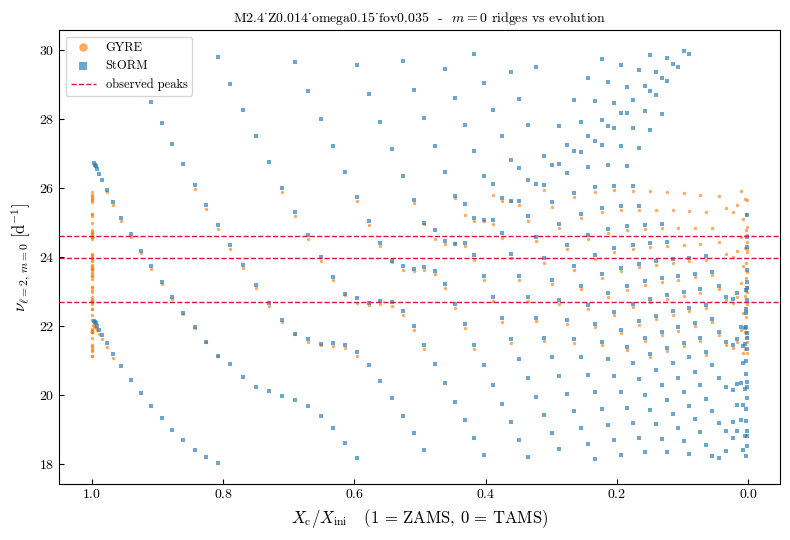


nearest-frequency offset where both have modes at the same profile:
  median 2.8164, max 8.7881 d^-1 (1,092 pairs)


In [32]:
TRACK_M, TRACK_Z, TRACK_FOV, TRACK_OMEGA = 2.4, 0.014, 0.035, 0.15
FREQ_LO, FREQ_HI = 18.0, 30.0
STORM_MIN_DOM = 0.5          # stricter than the matching cut: here the l
                             # label has to mean something
 
tid = f"M{TRACK_M:.1f}_Z{TRACK_Z:.3f}_omega{TRACK_OMEGA:.2f}_fov{TRACK_FOV:.3f}"
print(f"track {tid}")
 
mods = pd.read_parquet(MODELS_ALL_PARQUET)
mods = mods[mods.track_id.astype(str) == tid].copy()
mods["Xc_frac"] = mods["Xc"] / mods["Xc"].max()
print(f"  {len(mods)} profiles, X_c/X_ini {mods.Xc_frac.min():.3f} - "
      f"{mods.Xc_frac.max():.3f}")
 
# --- GYRE -----------------------------------------------------------------
gy = hd.load_modes(MODES_PARQUET, mode_type="p", l=2,
                   freq_lo=FREQ_LO, freq_hi=FREQ_HI)
gy = gy[(gy.track_id.astype(str) == tid) & (gy.m == 0)]
gy = gy.merge(mods[["profile", "Xc_frac"]], on="profile")
print(f"  GYRE : {len(gy):,} l=2 m=0 modes in [{FREQ_LO}, {FREQ_HI}] d^-1")
 
# --- StORM ----------------------------------------------------------------
filt = ((pc.field("freq_d") >= FREQ_LO) & (pc.field("freq_d") <= FREQ_HI)
        & (pc.field("m") == 0) & (pc.field("l") == 2)
        & (pc.field("dom_frac") >= STORM_MIN_DOM))
sm = pq.read_table(STORM_MODES_PARQUET,
                   columns=["track_id", "profile", "freq_d", "dom_frac"],
                   filters=filt).to_pandas()
sm = sm[sm.track_id.astype(str) == tid]
sm = sm.merge(mods[["profile", "Xc_frac"]], on="profile")
print(f"  StORM: {len(sm):,} l=2 m=0 modes with dom_frac>={STORM_MIN_DOM}")
 
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.scatter(gy.Xc_frac, gy.freq_d, s=6, color="tab:orange", alpha=0.65,
           lw=0, rasterized=True, label="GYRE")
ax.scatter(sm.Xc_frac, sm.freq_d, s=6, color="tab:blue", alpha=0.65,
           marker="s", lw=0, rasterized=True, label="StORM")
 
for f_o in p_obs["freq"]:
    ax.axhline(f_o, color="crimson", lw=1.0, ls="--", zorder=5)
ax.plot([], [], "--", color="crimson", lw=1.0, label="observed peaks")
ax.set_xscale("linear")
ax.invert_xaxis()
ax.set_xlabel(r"$X_{\rm c}/X_{\rm ini}$   (1 = ZAMS, 0 = TAMS)", fontsize=12)
ax.set_ylabel(r"$\nu_{\ell=2,\,m=0}\ [\rm d^{-1}]$", fontsize=12)
ax.set_title(f"{tid}  -  $m=0$ ridges vs evolution", fontsize=10)
ax.legend(fontsize=9, markerscale=2.5)
ax.tick_params(labelsize=10)
plt.tight_layout()
for ext in ("pdf", "png"):
    plt.savefig(f"pmode_ridges_vs_age.{ext}", bbox_inches="tight",
                pad_inches=0.02)
plt.show()
 
# Where the two colours sit on top of each other, the non-perturbative
# treatment adds nothing at m=0 and GYRE is adequate. Where they separate,
# StORM is finding l-mixing that shifts the mode itself, not just its
# splitting -- and that shift is invisible to any perturbative calculation.
if len(sm) and len(gy):
    both = (gy.rename(columns={"freq_d": "f_gyre"})[["profile", "f_gyre"]]
              .merge(sm.rename(columns={"freq_d": "f_storm"})
                       [["profile", "f_storm"]], on="profile"))
    if len(both):
        d = (both.f_storm - both.f_gyre).abs()
        print(f"\nnearest-frequency offset where both have modes at the same "
              f"profile:\n  median {d.median():.4f}, max {d.max():.4f} d^-1 "
              f"({len(both):,} pairs)")

MS  track M2.5_Z0.014_omega0.05_fov0.035: 89 profiles
PMS track M2.5_Z0.014_omega0.00_fov0.035: 283 profiles, Xc/Xini 0.9990-1 (flat, hence tau)
  GYRE  PMS: 66 l=2 m=0 modes, n_pg 0-25
  StORM MS : 297 l=2 m=0 modes with dom_frac >= 0.2, n_pg 0-18


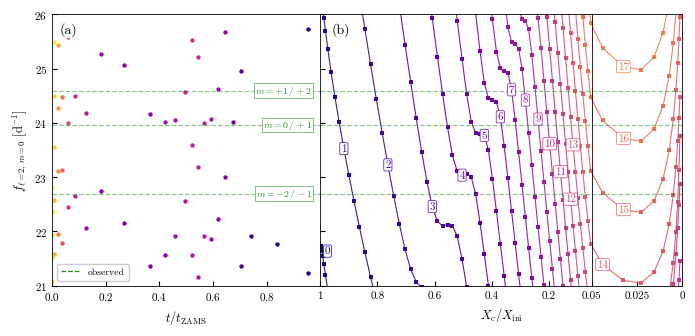


PMS/GYRE: orders passing within 0.05 d^-1 of an observed peak
  22.6911: n=7 @ tau 0.184, n=10 @ tau 0.0875
  23.9610: n=8 @ tau 0.42, n=10 @ tau 0.567, n=13 @ tau 0.0584
  24.5947: n=8 @ tau 0.619, n=10 @ tau 0.494

MS/StORM: orders passing within 0.05 d^-1 of an observed peak
  22.6911: n=2 @ Xc_frac 0.743, n=4 @ Xc_frac 0.457, n=8 @ Xc_frac 0.249, n=14 @ Xc_frac 0.00508, n=15 @ Xc_frac 0.0441
  23.9610: n=1 @ Xc_frac 0.934, n=4 @ Xc_frac 0.555
  24.5947: n=7 @ Xc_frac 0.331, n=13 @ Xc_frac 0.133, n=14 @ Xc_frac 0.108, n=15 @ Xc_frac 0.00361


In [33]:
# ==========================================================================
# p-mode ridges through the evolution: GYRE on the PMS | StORM on the MS
# ==========================================================================
# Each ridge is ONE radial order n_pg followed from profile to profile, so
# the reader sees the same mode drifting as the star's p-mode cavity
# contracts (PMS) or expands (MS), rather than a cloud of unrelated points.
# n_pg ridges never cross: where two would, they undergo an avoided
# crossing and exchange character instead, which shows up as a kink.
#
# Left : GYRE, PMS profiles, l=2 m=0. x = t/t_ZAMS (linear); X_c is flat
#        on the PMS, so it cannot be the clock there.
# Right: StORM, MS profiles, l=2 m=0 with dom_frac >= STORM_MIN_DOM, so the
#        n_pg label is the genuine dominant component. x = X_c/X_ini, with
#        the late MS stretched (below XC_BREAK) where the modes move fastest.
import pyarrow.compute as pc

# --- knobs ----------------------------------------------------------------
TRACK_M, TRACK_Z, TRACK_FOV = 2.5, 0.014, 0.035
MS_OMEGA   = 0.05            # StORM track (low rotation: clean dom_frac)
PMS_OMEGA  = PMS_KEEP_OMEGA  # PMS is identical across omega; use the copy
                             # the notebook keeps
FREQ_LO, FREQ_HI = 21.0, 26.0          # plotted window
PMS_MIN_TAU = 0.0            # drop PMS profiles before this t/t_ZAMS (the
                             # MESA relaxation models sit at t ~ 0)
LOAD_PAD   = 1.0             # load this much wider so ridges run off the edge
PMS_LOAD_PAD = 15.0          # PMS modes sweep through the window in one or
                             # two saved profiles, so load them MUCH wider:
                             # the line then runs between points outside the
                             # window and crosses it, instead of leaving an
                             # isolated dot
LABEL_SEP_PX = 16            # minimum spacing between ridge labels, pixels
STORM_MIN_DOM = 0.2          # the n_pg label must mean something here
PROFILE_GAP   = 3            # break a ridge after this many consecutive
                             # SAVED profiles without the mode (not raw
                             # profile numbers, which are saved unevenly)
MIN_POINTS    = 3            # ridges shorter than this are drawn, not labelled

XC_BREAK        = 0.05       # X_c/X_ini below which the axis is stretched
BREAK_AXIS_FRAC = 0.25       # fraction of the axis width given to the late MS
XC_TICKS        = (1.0, 0.8, 0.6, 0.4, 0.2, 0.05, 0.025, 0.0)
TAU_TICKS       = (0.0, 0.2, 0.4, 0.6, 0.8)   # 1 = ZAMS, shared edge

CM_ = 1 / 2.54
FIG_RC = {"font.size": 8, "axes.labelsize": 9,
          "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 7,
          "axes.linewidth": 0.6, "xtick.direction": "in",
          "ytick.direction": "in", "xtick.top": False, "ytick.right": False}

CMAP_NAME  = "plasma"
CMAP_RANGE = (0.0, 1.0)      # skip the palest end, which vanishes on white

# m for each observed peak (sorted by frequency), one tuple per assignment
# that reproduces the observed 2:1 gap ratio
M_ASSIGN = [(-2, 0, 1), (-1, 1, 2)]

def tid_for(omega):
    return f"M{TRACK_M:.1f}_Z{TRACK_Z:.3f}_omega{omega:.2f}_fov{TRACK_FOV:.3f}"

def xc_to_u(x, b=XC_BREAK, w=1 - BREAK_AXIS_FRAC):
    """X_c/X_ini (1 -> 0) to axis coordinate u (0 -> 1), late MS stretched."""
    x = np.asarray(x, dtype=float)
    return np.where(x >= b, w * (1 - x) / (1 - b), w + (1 - w) * (b - x) / b)

def n_color(n):
    lo, hi = N_RANGE
    frac = (n - lo) / max(hi - lo, 1)
    return plt.get_cmap(CMAP_NAME)(CMAP_RANGE[0]
                                   + frac * (CMAP_RANGE[1] - CMAP_RANGE[0]))

def ridges(df, xcol):
    """Yield (n_pg, segment), split where the mode is missing for more than
    PROFILE_GAP consecutive saved profiles."""
    for n, g in df.sort_values("prank").groupby("n_pg"):
        brk = np.flatnonzero(np.diff(g["prank"].to_numpy()) > PROFILE_GAP) + 1
        for a, b in zip(np.r_[0, brk], np.r_[brk, len(g)]):
            yield n, g.iloc[a:b].sort_values(xcol)

def draw(ax, df, xcol, marker):
    """Draw every ridge; return label candidates for place_labels()."""
    cands = {}
    for n, seg in ridges(df, xcol):
        c = n_color(n)
        ax.plot(seg[xcol], seg["freq_d"], "-", color=c, lw=0.8, alpha=0.9,
                zorder=2)
        ax.scatter(seg[xcol], seg["freq_d"], s=10, color=c, marker=marker,
                   lw=0, zorder=3, rasterized=True)
        inwin = seg[seg["freq_d"].between(FREQ_LO + 0.15, FREQ_HI - 0.15)]
        # keep the longest in-window stretch per n_pg as its candidates
        if len(inwin) >= MIN_POINTS and len(inwin) > len(cands.get(n, ((),))[0]):
            cands[n] = (inwin[xcol].to_numpy(), inwin["freq_d"].to_numpy(), c)
    return cands

def place_labels(ax, cands, sep=LABEL_SEP_PX, avoid_x=()):
    """Put one n_pg label on each ridge without overlapping the others.

    Each label may sit at any of its ridge's in-window points. Ridges with
    the fewest options are placed first; each takes the point closest to
    the middle of its ridge that is at least `sep` pixels from every label
    already placed, or failing that the point farthest from them. Call
    AFTER the axis limits are final: distances are measured on screen.
    """
    tr = ax.transData
    x_lo, x_hi = tr.transform([[ax.get_xlim()[0], 0], [ax.get_xlim()[1], 0]])[:, 0]
    walls = [x_lo, x_hi] + [tr.transform([[x, 0]])[0, 0] for x in avoid_x]
    placed = []
    for n in sorted(cands, key=lambda k: len(cands[k][0])):
        xs, ys, c = cands[n]
        pix = tr.transform(np.column_stack([xs, ys]))
        mid = (len(xs) - 1) / 2
        if placed:
            P = np.asarray(placed)
            dmin = np.sqrt(((pix[:, None, :] - P[None, :, :]) ** 2)
                           .sum(axis=2)).min(axis=1)
        else:
            dmin = np.full(len(xs), np.inf)
        # keep labels off the panel edges and the late-MS divider
        clear = np.min(np.abs(pix[:, [0]] - np.asarray(walls)[None, :]),
                       axis=1) > 0.6 * sep
        score = np.minimum(dmin, sep) * 1e3 - np.abs(np.arange(len(xs)) - mid)
        if clear.any():
            score = np.where(clear, score, -np.inf)
        i = int(np.argmax(score))
        placed.append(pix[i])
        # near a panel edge: anchor the box on its inner side so it sits
        # fully inside the frame, still touching its ridge point
        d_lo, d_hi = pix[i, 0] - x_lo, x_hi - pix[i, 0]
        if d_lo < sep:
            ha, dx = "left", 2
        elif d_hi < sep:
            ha, dx = "right", -2
        else:
            ha, dx = "center", 0
        ax.annotate(f"{int(n)}", (xs[i], ys[i]), xytext=(dx, 0),
                    textcoords="offset points", fontsize=8, color=c,
                    ha=ha, va="center", zorder=9, annotation_clip=False,
                    bbox=dict(boxstyle="round,pad=0.12", fc="white",
                              ec=c, lw=0.5))


# --- models ---------------------------------------------------------------
mods = pd.read_parquet(MODELS_ALL_PARQUET)
mods["track_id"] = mods["track_id"].astype(str)

stem = f"M{TRACK_M:.1f}_Z{TRACK_Z:.3f}_omega"
avail = sorted(mods.loc[mods.track_id.str.startswith(stem)
                        & mods.track_id.str.endswith(f"_fov{TRACK_FOV:.3f}"),
                        "track_id"].str.extract(r"omega([\d.]+)")[0]
               .astype(float).unique())
for om in (MS_OMEGA, PMS_OMEGA):
    if not np.isclose(avail, om).any():
        raise ValueError(f"no track {tid_for(om)}; omega values in the grid "
                         f"for this M, Z, fov: {avail}")

ms_mod = mods[(mods.track_id == tid_for(MS_OMEGA)) & (mods.phase == "MS")].copy()
pms_mod = mods[(mods.track_id == tid_for(PMS_OMEGA)) & (mods.phase == "PMS")].copy()

ms_mod["Xc_frac"] = ms_mod["Xc"] / ms_mod["Xc"].max()
# X_c does not move on the PMS (no hydrogen burning), so the PMS clock is
# the age normalised to the ZAMS: 0 at the start of the track, 1 at the ZAMS
pms_mod["tau"] = pms_mod["age_Myr"] / pms_mod["age_Myr"].max()
pms_mod = pms_mod[pms_mod["tau"] >= PMS_MIN_TAU]
for m_ in (ms_mod, pms_mod):
    m_["prank"] = m_["profile"].rank(method="dense").astype(int)

print(f"MS  track {tid_for(MS_OMEGA)}: {len(ms_mod)} profiles")
print(f"PMS track {tid_for(PMS_OMEGA)}: {len(pms_mod)} profiles, "
      f"Xc/Xini {pms_mod.Xc.min()/pms_mod.Xc.max():.4f}-1 (flat, hence tau)")

# --- GYRE, PMS --------------------------------------------------------------
gy = hd.load_modes(MODES_PARQUET, mode_type="p", l=2, m=0,
                   freq_lo=max(FREQ_LO - PMS_LOAD_PAD, 0.0),
                   freq_hi=FREQ_HI + PMS_LOAD_PAD)
gy["track_id"] = gy["track_id"].astype(str)
gy = gy[gy.track_id == tid_for(PMS_OMEGA)]
gy = gy.merge(pms_mod[["profile", "tau", "prank"]], on="profile")
print(f"  GYRE  PMS: {len(gy):,} l=2 m=0 modes, "
      f"n_pg {gy.n_pg.min()}-{gy.n_pg.max()}")

# --- StORM, MS --------------------------------------------------------------
filt = ((pc.field("freq_d") >= FREQ_LO - LOAD_PAD)
        & (pc.field("freq_d") <= FREQ_HI + LOAD_PAD)
        & (pc.field("m") == 0) & (pc.field("l") == 2)
        & (pc.field("dom_frac") >= STORM_MIN_DOM))
sm = pq.read_table(STORM_MODES_PARQUET,
                   columns=["track_id", "profile", "n_pg", "freq_d",
                            "dom_frac"], filters=filt).to_pandas()
sm["track_id"] = sm["track_id"].astype(str)
sm = sm[sm.track_id == tid_for(MS_OMEGA)]
# one mode per (profile, n_pg): the cleanest
sm = (sm.sort_values("dom_frac", ascending=False)
        .drop_duplicates(["profile", "n_pg"]))
sm = sm.merge(ms_mod[["profile", "Xc_frac", "prank"]], on="profile")
sm["u"] = xc_to_u(sm["Xc_frac"])
print(f"  StORM MS : {len(sm):,} l=2 m=0 modes with dom_frac >= "
      f"{STORM_MIN_DOM}, n_pg {sm.n_pg.min()}-{sm.n_pg.max()}")

N_RANGE = (min(gy.n_pg.min(), sm.n_pg.min()), max(gy.n_pg.max(), sm.n_pg.max()))
# --- figure -----------------------------------------------------------------
with plt.rc_context(FIG_RC):
    fig, (axp, axm) = plt.subplots(
        1, 2, figsize=(17.6 * CM_, 8.2 * CM_), sharey=True,
        gridspec_kw=dict(width_ratios=[1, 1.35], wspace=0.0))
    X_PAD = 0.0                      # fraction of each panel's width

    # (a) PMS: panels meet at the ZAMS, so tau = 1 is the shared edge
    cand_p = draw(axp, gy, "tau", "o")
    axp.set_xlim(PMS_MIN_TAU, 1.0)
    axp.set_xticks(TAU_TICKS)
    axp.set_xlabel(r"$t/t_{\rm ZAMS}$")
    axp.set_ylabel(r"$f_{\ell=2,\,m=0}\ [\rm d^{-1}]$")

    # (b) MS, with the late MS split off by a solid line
    cand_m = draw(axm, sm, "u", "s")
    axm.set_xlim(0-X_PAD, 1)
    ticks = [t for t in XC_TICKS if 0 <= t <= 1]
    axm.set_xticks(xc_to_u(ticks))
    axm.set_xticklabels([f"{t:g}" for t in ticks])
    axm.axvline(xc_to_u(XC_BREAK), color="k",
                lw=FIG_RC["axes.linewidth"], zorder=7)
    axm.set_xlabel(r"$X_{\rm c}/X_{\rm ini}$")

    for ax, lab in ((axp, "(a)"), (axm, "(b)")):
        # the two possible m for each observed peak, inside panel (a) at the ZAMS
        def _m(v):
            return "0" if v == 0 else f"{v:+d}"
        for j, f_o in enumerate(np.sort(p_obs["freq"].to_numpy())):
            txt = r"$m = " + r"\,/\,".join(_m(a[j]) for a in M_ASSIGN) + "$"
            axp.text(0.97, f_o, txt, transform=axp.get_yaxis_transform(),
                    ha="right", va="center", fontsize=7, color="forestgreen",
                    zorder=9,
                    bbox=dict(boxstyle="square,pad=0.1", fc="white",
                           ec=(0.133, 0.545, 0.133, 0.6), lw=0.5))
            
        for f_o in p_obs["freq"]:
            ax.axhline(f_o, color="forestgreen", alpha=0.5, lw=0.9, ls="--", zorder=4)
        ax.set_ylim(FREQ_LO, FREQ_HI)
        ax.text(0.03, 0.97, lab, transform=ax.transAxes, va="top",
                ha="left", fontsize=10, fontweight="bold", zorder=10,
                bbox=dict(boxstyle="square,pad=0.1", fc="white", ec="none",
                          lw=0.5, alpha=0.85))
        for sp in ax.spines.values():
            sp.set_zorder(8)       # frame above markers (3) and lines (2)
    axp.plot([], [], "--", color="forestgreen", lw=0.9, label="observed")
    axp.legend(loc="lower left", frameon=True, framealpha=1.0)

    fig.subplots_adjust(left=0.075, right=0.985, bottom=0.14, top=0.98)
    fig.canvas.draw()                    # fix the layout before measuring
    place_labels(axp, cand_p)
    place_labels(axm, cand_m, avoid_x=[float(xc_to_u(XC_BREAK))])
    for ext in ("pdf", "png"):
        fig.savefig(f"pmode_ridges_pms_ms.{ext}", dpi=300)
    plt.show()

# which orders cross the observed peaks, and when -- the numbers behind
# the picture
for lab, df, xcol in (("PMS/GYRE", gy, "tau"), ("MS/StORM", sm, "Xc_frac")):
    print(f"\n{lab}: orders passing within 0.05 d^-1 of an observed peak")
    for f_o in np.sort(p_obs["freq"].to_numpy()):
        hit = df[(df.freq_d - f_o).abs() < 0.05]
        s = ", ".join(f"n={int(n)} @ {xcol} {g[xcol].median():.3g}"
                      for n, g in hit.groupby("n_pg"))
        print(f"  {f_o:.4f}: {s or '-'}")

## 4. The grids in the HRD

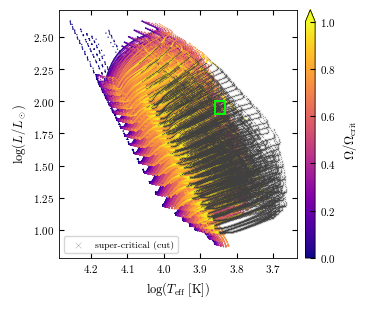

298,591 MS models
27,965 super-critical


In [34]:
# ==========================================================================
# APPENDIX: MS grid in the HRD, coloured by the critical rotation fraction
# ==========================================================================
# Super-critical models are drawn as crosses rather than dropped, so the
# region they occupy is visible instead of silently absent.

OCRIT_COL   = "surf_avg_omega_div_omega_crit"
CMAP        = "plasma"
PHASE_SHOWN = "MS"          # PMS structures are non-rotating: colour is 0
CM_         = 1/2.54

FIG_RC = {"font.size": 8, "axes.labelsize": 9,
          "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 7,
          "axes.linewidth": 0.6, "xtick.direction": "in",
          "ytick.direction": "in", "xtick.top": True, "ytick.right": True}

d = pd.read_parquet(MODELS_ALL_PARQUET)
d = d[(d["phase"] == PHASE_SHOWN) & d[OCRIT_COL].notna()].copy()
d["logL"] = np.log10(d["L"])
d["logT"] = np.log10(d["Teff"])

norm = Normalize(vmin=0.0, vmax=1.0)
sub_crit = d[d[OCRIT_COL] <= 1.0]
sup_crit = d[d[OCRIT_COL] > 1.0]

with plt.rc_context(FIG_RC):
    fig, ax = plt.subplots(figsize=(8.8*CM_, 7.6*CM_))

    # order by ratio so the fastest rotators are drawn on top and are not
    # hidden under the bulk of slow ones
    o = np.argsort(sub_crit[OCRIT_COL].to_numpy())
    sc = ax.scatter(sub_crit["logT"].to_numpy()[o],
                    sub_crit["logL"].to_numpy()[o],
                    c=sub_crit[OCRIT_COL].to_numpy()[o], cmap=CMAP,
                    norm=norm, s=0.9, lw=0, rasterized=True, zorder=2)
    ax.scatter(sup_crit["logT"], sup_crit["logL"], s=1.1,
               marker="x", lw=0.3, color="0.25", alpha=0.5,
               rasterized=True, zorder=3, label="super-critical (cut)")

    ax.add_patch(Rectangle((np.log10(TEFF_BOX[0]), np.log10(L_BOX[0])),
                           np.log10(TEFF_BOX[1]) - np.log10(TEFF_BOX[0]),
                           np.log10(L_BOX[1]) - np.log10(L_BOX[0]),
                           fill=False, edgecolor="lime", lw=1.4, zorder=8))

    ax.set_xlabel(r"$\log (T_{\rm eff}\ [\rm K])$")
    ax.set_ylabel(r"$\log (L/L_\odot)$")
    ax.invert_xaxis()
    ax.legend(loc="lower left", frameon=True, markerscale=4)

    fig.subplots_adjust(left=0.135, right=0.82, bottom=0.14, top=0.97)
    cax = fig.add_axes([0.845, 0.14, 0.028, 0.83])
    cb = fig.colorbar(sc, cax=cax, extend="max")
    cb.set_label(r"$\Omega/\Omega_{\rm crit}$", fontsize=9)
    cb.ax.tick_params(labelsize=8)

    for ext in ("pdf", "png"):
        fig.savefig(f"hrd_by_omega_crit.{ext}", dpi=300)
    plt.show()

    print(f"{len(d):,} {PHASE_SHOWN} models\n"
          f"{len(sup_crit):,} super-critical")

sub-critical at f_obs: MS 293,675/298,591, PMS 119,306


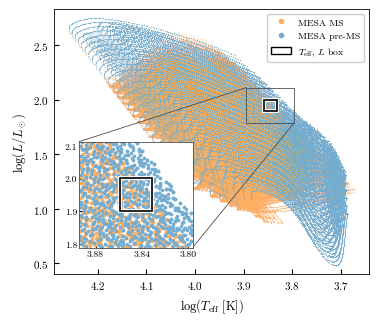

box: Teff 6778-7231 K, L 79.5-100.5 Lsun

grid                models   in box  nearest (dex)   L max  M max
MESA MS            293,675      490          0.000   422.7   4.20
MESA PMS           119,306      710          0.000   562.2   4.20
Innsbruck PMS      177,741        0          0.057    77.8   2.50


In [39]:
# ==========================================================================
# HRD: MESA grid (MS + PMS) with zoom on the box  |  Innsbruck PMS vs the box
# ==========================================================================
# (a) IvS MESA grid, both phases, with an inset zoomed on the Teff-L box.
#     The inset is THINNED (at most INSET_PER_BIN models per cell of a
#     regular grid) so it shows where models exist near the box rather than
#     a solid block of overplotted tracks. Thinning is display-only.
# (b) Innsbruck PMS grid, same axes and same box, no zoom.
# No constant-radius lines in either panel.
import matplotlib.patheffects as pe
from matplotlib.ticker import FormatStrFormatter, MaxNLocator
from matplotlib.patches import ConnectionPatch

CM_ = 1 / 2.54
FIG_RC = {"font.size": 8, "axes.labelsize": 9,
          "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 7,
          "axes.linewidth": 0.6, "xtick.direction": "in",
          "ytick.direction": "in", "xtick.top": False, "ytick.right": False}

# Light, desaturated track colours so the black box stands out on top of
# them; the box also gets a white halo so it reads over any colour.
COL_MS, COL_PMS, COL_INN = "#fdae61", "#74add1", "#ae9ff0"
BOX_COLOR = "k"

# --- knobs ----------------------------------------------------------------
APPLY_CUTS   = False   # True: run apply_model_filters (supercritical cut etc.)
INSET_RECT   = [0.08, 0.10, 0.36, 0.40]   # x0, y0, w, h in AXES fraction
INSET_PAD    = (0.035, 0.11)              # dex around the box: (logT, logL)
# which corners the two zoom lines join, as (inset corner, zoom-box corner).
# Corners are as they APPEAR on the page (the Teff axis is inverted).
INSET_LINKS  = [("lower left", "lower left"), ("upper right", "lower right")]
INSET_NBIN   = 22                         # thinning grid: bins per axis
INSET_PER_BIN = 2                         # max models kept per bin per phase
XLIM = None            # (logT_hot, logT_cool), e.g. (4.25, 3.60); None = auto
YLIM = None            # (logL_lo, logL_hi);                       None = auto


def prep(df):
    df = df.copy()
    df["logT"] = np.log10(df["Teff"])
    df["logL"] = np.log10(df["L"])
    return df


def thin(df, xlim, ylim, nbin, per_bin, seed=0):
    """Keep <= per_bin models in each cell of an nbin x nbin grid over the window."""
    w = df[df["logT"].between(*xlim) & df["logL"].between(*ylim)]
    w = w.sample(frac=1.0, random_state=seed)             # random within a cell
    ix = np.clip(((w["logT"] - xlim[0]) / (xlim[1] - xlim[0]) * nbin)
                 .to_numpy().astype(int), 0, nbin - 1)
    iy = np.clip(((w["logL"] - ylim[0]) / (ylim[1] - ylim[0]) * nbin)
                 .to_numpy().astype(int), 0, nbin - 1)
    w = w.assign(_cell=ix * nbin + iy)
    return w.groupby("_cell", sort=False).head(per_bin)


# --- data -----------------------------------------------------------------
ivs = pd.read_parquet(MODELS_ALL_PARQUET)
if APPLY_CUTS:
    ivs = apply_model_filters(ivs, "GYRE_MESA", verbose=False)
ivs = prep(ivs[ivs["phase"].isin(["MS", "PMS"])])
 
ms_all = ivs[ivs["phase"] == "MS"]
ms = ms_all[subcritical_mask(ms_all)]          # a FRAME, not the mask
pms = ivs[ivs["phase"] == "PMS"]
pms = pms[pms["omega"].isna()
          | np.isclose(pms["omega"].fillna(-1), PMS_KEEP_OMEGA)]
pms = pms[subcritical_mask(pms)]               # same criterion for both
print(f"sub-critical at f_obs: MS {len(ms):,}/{len(ms_all):,}, "
      f"PMS {len(pms):,}")
inn = prep(pd.read_parquet(INN_MODELS_PARQUET).query("phase == 'PMS'"))

# --- geometry -------------------------------------------------------------
tlo, thi = np.log10(TEFF_BOX)
llo, lhi = np.log10(L_BOX)

allT = np.concatenate([ms["logT"], pms["logT"], inn["logT"]])
allL = np.concatenate([ms["logL"], pms["logL"], inn["logL"]])
xlim = XLIM or (allT.max() + 0.03, allT.min() - 0.03)
ylim = YLIM or (allL.min() - 0.08, allL.max() + 0.08)

iwin_x = (tlo - INSET_PAD[0], thi + INSET_PAD[0])
iwin_y = (llo - INSET_PAD[1], lhi + INSET_PAD[1])


def draw_box(a, lw):
    a.add_patch(Rectangle((tlo, llo), thi - tlo, lhi - llo, fill=False,
                          edgecolor=BOX_COLOR, lw=lw, zorder=8,
                          path_effects=[pe.Stroke(linewidth=lw + 1.6,
                                                  foreground="white"),
                                        pe.Normal()]))


# --- figure ---------------------------------------------------------------
with plt.rc_context(FIG_RC):
    fig, axa= plt.subplots(figsize=(8.8 * CM_, 8.2 * CM_))

    # (a) full HRD, MESA MS + PMS
    kw = dict(s=0.7, lw=0, alpha=0.30, rasterized=True)
    axa.scatter(ms["logT"], ms["logL"], color=COL_MS, zorder=2, **kw)
    axa.scatter(pms["logT"], pms["logL"], color=COL_PMS, zorder=3, **kw)
    draw_box(axa, 1.2)

    # inset, thinned
    axi = axa.inset_axes(INSET_RECT)
    axi.set_facecolor("white")
    ikw = dict(s=7, lw=0, alpha=1.0, rasterized=True)
    axi.scatter(*thin(ms, iwin_x, iwin_y, INSET_NBIN,
                      INSET_PER_BIN)[["logT", "logL"]].to_numpy().T,
                color=COL_MS, zorder=2, **ikw)
    axi.scatter(*thin(pms, iwin_x, iwin_y, INSET_NBIN,
                      INSET_PER_BIN)[["logT", "logL"]].to_numpy().T,
                color=COL_PMS, zorder=3, **ikw)
    draw_box(axi, 1.2)
    axi.set_xlim(iwin_x[1], iwin_x[0])          # hot on the left
    axi.set_ylim(*iwin_y)
    axi.xaxis.set_major_locator(MaxNLocator(3))
    axi.yaxis.set_major_locator(MaxNLocator(4))
    axi.xaxis.set_major_formatter(FormatStrFormatter("%.2f"))
    axi.yaxis.set_major_formatter(FormatStrFormatter("%.1f"))
    axi.tick_params(labelsize=7, length=2, pad=1.5)
    for sp in axi.spines.values():
        sp.set_edgecolor("0.3")
        sp.set_zorder(10)          # frame drawn on top of the markers
    # zoom rectangle + connector lines drawn by hand, so the corners are ours
    axa.add_patch(Rectangle((iwin_x[0], iwin_y[0]), iwin_x[1] - iwin_x[0],
                            iwin_y[1] - iwin_y[0], fill=False,
                            edgecolor="0.3", lw=0.6, zorder=4.5))
    # on-page corners: left = hot = larger logT, because the x axis is inverted
    box_xy = {"lower left":  (iwin_x[1], iwin_y[1]),
              "upper left":  (iwin_x[1], iwin_y[0]),
              "lower right": (iwin_x[0], iwin_y[0]),
              "upper right": (iwin_x[0], iwin_y[1])}
    ins_xy = {"lower left": (0, 1), "upper left": (0, 0),
              "lower right": (1, 1), "upper right": (1, 0)}
    for c_ins, c_box in INSET_LINKS:
        axa.add_artist(ConnectionPatch(
            xyA=ins_xy[c_ins], coordsA=axi.transAxes,
            xyB=box_xy[c_box], coordsB=axa.transData,
            color="0.3", lw=0.6, zorder=4.5))

    # (b) Innsbruck PMS grid vs the box
    # axb.scatter(inn["logT"], inn["logL"], s=0.7, lw=0, alpha=0.30,
    #             color=COL_INN, rasterized=True, zorder=2)
    # draw_box(axb, 1.2)

    axa.set_xlim(*xlim)                         # sharex: also sets axb
    axa.set_ylim(*ylim)
    # for ax, lab in ((axa, "(a)"), (axb, "(b)")):
    axa.set_xlabel(r"$\log (T_{\rm eff}\ [\rm K])$")
    # axa.text(0.03, 0.97, "(a)", transform=axa.transAxes, va="top", ha="left",
    #         fontsize=10, fontweight="bold",
    #         bbox=dict(boxstyle="square,pad=0.25", fc="white", ec="none",
    #                     alpha=0.85), zorder=10)
    axa.set_ylabel(r"$\log (L/L_\odot)$")
    # axb.tick_params(labelleft=False)

    # one legend per panel, inside the axes, same style as the other figures
    dot = lambda c, lab: Line2D([], [], ls="", marker="o", ms=3, color=c,
                                label=lab)
    box_h = Rectangle((0, 0), 1, 1, fill=False, edgecolor=BOX_COLOR, lw=1.0,
                      label=r"$T_{\rm eff}$, $L$ box")
    axa.legend(handles=[dot(COL_MS, "MESA MS"), dot(COL_PMS, "MESA pre-MS"),
                        box_h], loc="upper right", frameon=True,
               framealpha=1.0)
    # axb.legend(handles=[dot(COL_INN, "Innsbruck PMS"), box_h],
    #            loc="lower left", frameon=True)
    fig.subplots_adjust(left=0.075, right=0.985, bottom=0.15, top=0.97,
                        wspace=0.04)

    for ext in ("pdf", "png"):
        fig.savefig(f"hrd_grids_box_inset.{ext}", dpi=300)
    plt.show()

# --- what the figure claims, in numbers -------------------------------------
def box_dist(df):
    """Distance (dex, HRD plane) from each model to the box; 0 inside it."""
    dx = np.maximum.reduce([tlo - df["logT"], np.zeros(len(df)), df["logT"] - thi])
    dy = np.maximum.reduce([llo - df["logL"], np.zeros(len(df)), df["logL"] - lhi])
    return np.hypot(dx, dy)

print(f"box: Teff {TEFF_BOX[0]:.0f}-{TEFF_BOX[1]:.0f} K, "
      f"L {L_BOX[0]:.1f}-{L_BOX[1]:.1f} Lsun\n")
print(f"{'grid':<16}{'models':>10}{'in box':>9}{'nearest (dex)':>15}"
      f"{'L max':>8}{'M max':>7}")
for lab, d, mcol in (("MESA MS", ms, "star_mass"), ("MESA PMS", pms, "star_mass"),
                     ("Innsbruck PMS", inn, "M")):
    dist = box_dist(d)
    mmax = d[mcol].max() if mcol in d else np.nan
    print(f"{lab:<16}{len(d):>10,}{(dist == 0).sum():>9,}{dist.min():>15.3f}"
          f"{d['L'].max():>8.1f}{mmax:>7.2f}")

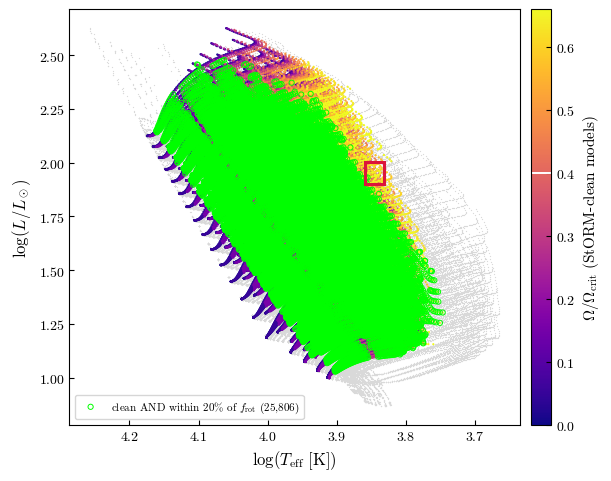

count    120633.000000
mean          0.167210
std           0.167212
min           0.000000
25%           0.049763
50%           0.151559
75%           0.271285
max           0.749786
Name: surf_avg_omega_div_omega_crit, dtype: float64
clean models within 20% of f_rot: 25,806 of 120,633


In [22]:
# --- Load data and compute STORM clean models ---
d = pd.read_parquet(MODELS_ALL_PARQUET)
d = d[(d["phase"] == "MS") & d["surf_avg_omega_div_omega_crit"].notna()].copy()
d["logL"] = np.log10(d["L"])
d["logT"] = np.log10(d["Teff"])

NONZERO_M = [-2, -1, 1, 2]

def storm_quality4(path=STORM_MODES_PARQUET):
    """One row per model, with three independent structural tests.

    over          n_deformed - n_basis per m. An eigenproblem cannot return
                  more eigenvalues than basis states, so > 0 is IMPOSSIBLE.
                  No threshold, no window dependence.
    basis_imbal   max/min of n_basis over |m|>0. The basis is every even-degree
                  mode at that m, so these must be IDENTICAL: exactly 1.0.
                  Uses the basis, not the mode counts, so a frequency window
                  clipping a few deformed modes cannot trip it.
    m0_excess     n_basis(m=0) - n_basis(|m|>0). Only m=0 can contain l=0
                  modes, so this is strictly positive and equals n(l=0).
    """
    cnt = pq.read_table(path, columns=["track_id", "profile", "m",
                                       "n_deformed", "n_basis"]).to_pandas()

    # n_deformed / n_basis are constant within an m block; `first` not `sum`
    g = (cnt.groupby(["track_id", "profile", "m"], observed=True)
            .agg(n_rows=("m", "size"),
                 n_def=("n_deformed", "first"),
                 n_bas=("n_basis", "first"))
            .reset_index())
    g["over"] = g["n_def"] - g["n_bas"]

    q = (g.groupby(["track_id", "profile"], observed=True)
           .agg(worst_over=("over", "max"),
                n_rows=("n_rows", "sum"),
                n_def_tot=("n_def", "sum"))
           .reset_index())

    b = g.pivot_table(index=["track_id", "profile"], columns="m",
                      values="n_bas", observed=True)
    have = [m for m in NONZERO_M if m in b.columns]
    bb = pd.DataFrame({
        "n_bas_m0":     b[0] if 0 in b.columns else np.nan,
        "n_bas_nz_max": b[have].max(axis=1),
        "n_bas_nz_min": b[have].min(axis=1),
    }).reset_index()
    q = q.merge(bb, on=["track_id", "profile"], how="left")

    q["basis_imbal"] = q.n_bas_nz_max / q.n_bas_nz_min.replace(0, np.nan)
    q["m0_excess"] = q.n_bas_m0 - q.n_bas_nz_max

    q["over_ok"] = q.worst_over <= 0
    q["imbal_ok"] = q.basis_imbal == 1.0
    q["m0_ok"] = q.m0_excess > 0
    q["clean"] = q.over_ok
    return q


sq = storm_quality4()
storm_clean = sq[sq["clean"]]

# Merge to get STORM clean models in the main DataFrame
storm_clean_models = d.merge(
    storm_clean[["track_id", "profile"]],
    on=["track_id", "profile"],
    how="inner"
)

CMAP2 = "Greys"

# --- Single-panel plot ---
fig, ax = plt.subplots(figsize=(7, 5.4))

# background: every MS model, one flat grey
ax.scatter(d["logT"], d["logL"], s=0.8, color="0.85", lw=0,
           rasterized=True, zorder=1)

# the models that pass, coloured by what actually matters
s = storm_clean_models.sort_values(OCRIT_COL)
sc = ax.scatter(s["logT"], s["logL"], c=s[OCRIT_COL], cmap="plasma",
                vmin=0, vmax=s[OCRIT_COL].quantile(0.99),
                s=2.5, lw=0, rasterized=True, zorder=3)

cb = fig.colorbar(sc, ax=ax, pad=0.02)
cb.set_label(r"$\Omega/\Omega_{\rm crit}$ (StORM-clean models)", fontsize=11)
cb.ax.axhline(0.4, color="w", lw=1.4)

ax.add_patch(Rectangle((np.log10(TEFF_BOX[0]), np.log10(L_BOX[0])),
                    np.log10(TEFF_BOX[1]) - np.log10(TEFF_BOX[0]),
                    np.log10(L_BOX[1]) - np.log10(L_BOX[0]),
                    fill=False, edgecolor="crimson", lw=2.2,
                    zorder=8))
# what fraction of clean models rotate fast enough?
need = (s["f_rot_model_cpd"] / F_ROT_CPD - 1).abs() < 0.2
ax.scatter(s.loc[need, "logT"], s.loc[need, "logL"], s=14,
           facecolor="none", edgecolor="lime", lw=0.7, zorder=5,
           label=f"clean AND within 20% of $f_{{\\rm rot}}$ ({need.sum():,})")
ax.legend(fontsize=8, loc="lower left")

ax.set_ylabel(r"$\log (L/L_\odot)$", fontsize=12)
ax.set_xlabel(r"$\log (T_{\rm eff}\ [\rm K])$", fontsize=12)
ax.tick_params(labelsize=10)
ax.invert_xaxis()
# Save and show
for ext in ("pdf", "png"):
    plt.savefig(f"hrd_by_omega_crit_storm_clean.{ext}", bbox_inches="tight", pad_inches=0.02)
plt.show()

print(s[OCRIT_COL].describe())
print(f"clean models within 20% of f_rot: {need.sum():,} of {len(s):,}")

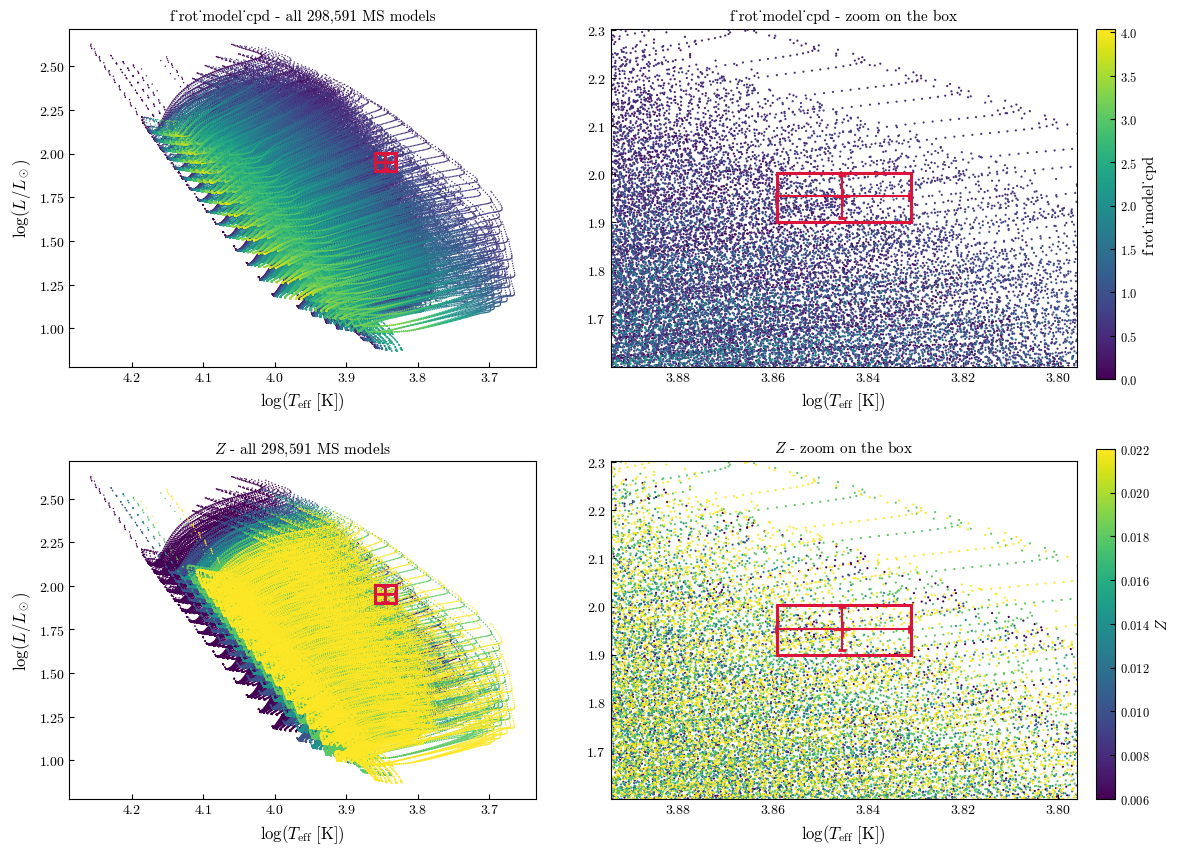

MS models: 298,591   in the box: 566

inside the box, by f_rot_model_cpd:
                  n   Teff_lo   Teff_hi     L_lo     L_hi  ocrit_max
f_rot_model_cpd                                                     
0.000000         16  7062.578  7206.120   79.583   92.681      0.000
0.043812          1  7065.304  7065.304   89.474   89.474      0.050
0.044169          1  7056.108  7056.108   88.017   88.017      0.050
0.044222          1  7112.453  7112.453   91.323   91.323      0.050
0.045063          1  7076.918  7076.918   87.068   87.068      0.050
0.045295          1  7192.390  7192.390   93.527   93.527      0.051
0.046128          1  7109.712  7109.712   86.467   86.467      0.051
0.047281          1  7148.029  7148.029   86.031   86.031      0.051
0.047293          1  7105.619  7105.619   83.030   83.030      0.051
0.047383          1  7084.649  7084.649   81.631   81.631      0.051
0.047995          1  7163.116  7163.116   84.774   84.774      0.052
0.048189          1  7097.842

In [23]:
# ==========================================================================
# HRD COLOURED BY f_ov AND Z
# ==========================================================================
# Same layout as the omega/omega_crit version, but these are DISCRETE grid
# axes (5 values each), so a continuous colourbar would imply a resolution
# the grid does not have. Coloured with a boundary norm instead: one colour
# per grid value, ticks at the values themselves.
PHASE_SHOWN = "MS"
PANEL_COLS = ["f_rot_model_cpd", "Z"]
LABELS = {"f_rot_cpd": r"$f_{\rm rot,cpd}$", "Z": r"$Z$",
          "omega": r"$\Omega/\Omega_{\rm crit}$ at ZAMS"}

d = pd.read_parquet(MODELS_ALL_PARQUET)
d = d[d["phase"] == PHASE_SHOWN].copy()
d["logL"] = np.log10(d["L"])
d["logT"] = np.log10(d["Teff"])
in_box = d["Teff"].between(*TEFF_BOX) & d["L"].between(*L_BOX)

fig, axes = plt.subplots(len(PANEL_COLS), 2, figsize=(13, 5.0 * len(PANEL_COLS)))

for row, col in enumerate(PANEL_COLS):
    # Use a continuous colormap and normalization
    cmap = plt.cm.viridis
    norm = plt.Normalize(d[col].min(), d[col].max())

    for k, zoom in enumerate((False, True)):
        ax = axes[row][k]
        o = np.argsort(d[col].to_numpy())
        sc = ax.scatter(
            d["logT"].to_numpy()[o],
            d["logL"].to_numpy()[o],
            c=d[col].to_numpy()[o],
            cmap=cmap,
            norm=norm,
            s=2.5 if zoom else 1.0,
            lw=0,
            rasterized=True,
            zorder=2,
        )

        ax.add_patch(Rectangle((np.log10(TEFF_BOX[0]), np.log10(L_BOX[0])),
                               np.log10(TEFF_BOX[1]) - np.log10(TEFF_BOX[0]),
                               np.log10(L_BOX[1]) - np.log10(L_BOX[0]),
                               fill=False, edgecolor="crimson", lw=2.2,
                               zorder=8))
        ax.errorbar(OBS["logTeff"][0], OBS["logL"][0],
                    xerr=OBS["logTeff"][1], yerr=OBS["logL"][1], fmt="+",
                    color="crimson", ms=11, mew=2, capsize=3, zorder=9)

        ax.set_xlabel(r"$\log (T_{\rm eff}\ [\rm K])$", fontsize=12)
        ax.tick_params(labelsize=10)
        ax.invert_xaxis()
        if zoom:
            ax.set_xlim(np.log10(TEFF_BOX[1]) + 0.035,
                        np.log10(TEFF_BOX[0]) - 0.035)
            ax.set_ylim(np.log10(L_BOX[0]) - 0.30, np.log10(L_BOX[1]) + 0.30)
            ax.set_title(f"{LABELS.get(col, col)} - zoom on the box",
                         fontsize=11)
        else:
            ax.set_ylabel(r"$\log (L/L_\odot)$", fontsize=12)
            ax.set_title(f"{LABELS.get(col, col)} - all {len(d):,} "
                         f"{PHASE_SHOWN} models", fontsize=11)

    pos = axes[row][1].get_position()
    cax = fig.add_axes([0.915, pos.y0, 0.014, pos.height])
    cb = fig.colorbar(sc, cax=cax)
    cb.set_label(LABELS.get(col, col), fontsize=11)
    cb.ax.tick_params(labelsize=9)

fig.subplots_adjust(right=0.90, wspace=0.16, hspace=0.28)
for ext in ("pdf", "png"):
    plt.savefig("hrd_by_fov_Z.%s" % ext, bbox_inches="tight", pad_inches=0.02)
plt.show()

# --- what actually reaches the box ---------------------------------------
print(f"{PHASE_SHOWN} models: {len(d):,}   in the box: {in_box.sum():,}\n")
b = d[in_box]
for col in PANEL_COLS:
    agg = {"n": (col, "size"), "Teff_lo": ("Teff", "min"),
           "Teff_hi": ("Teff", "max"), "L_lo": ("L", "min"),
           "L_hi": ("L", "max")}
    if OCRIT_COL in b.columns:
        agg["ocrit_max"] = (OCRIT_COL, "max")
    print(f"inside the box, by {col}:")
    print(b.groupby(col, observed=True).agg(**agg).round(3).to_string())
    # a value present in the grid but absent from the box is excluded by the
    # spectroscopic constraint alone, before any seismology
    missing = sorted(set(d[col].dropna().unique()) - set(b[col].dropna().unique()))
    if missing:
        print(f"  NOT represented in the box: {missing}")
    print()

# The joint view is what matters: the box may be reachable at several fov and
# Z values, but only in combination with a particular rotation.
if OCRIT_COL in b.columns:
    piv = (b.pivot_table(index="fov", columns="Z", values=OCRIT_COL,
                         aggfunc="size", observed=True).fillna(0).astype(int))
    print("models in the box, fov (rows) x Z (columns):")
    print(piv.to_string())


## 5. Box checks

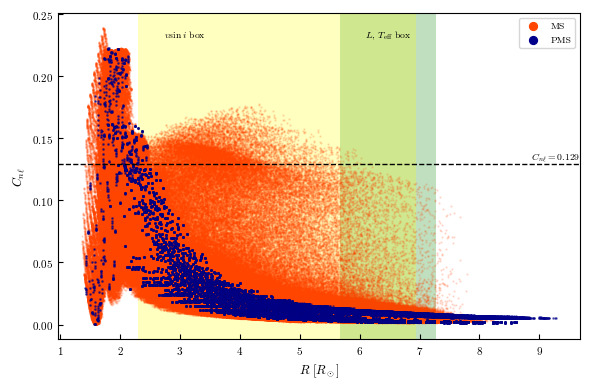

L/Teff box implies R in [5.68, 7.27] R_sun

C_nl within that radius range (the joint constraint):
         count       min       50%       max
phase                                       
MS     39377.0  0.001307  0.008182  0.140969
PMS    56135.0  0.001642  0.003751  0.013190
  MS: max C = 0.1410  -> reaches requirement
  PMS: max C = 0.0132  -> short of requirement by 90%


In [24]:
# --- the joint exclusion: C_nl requirement AND the luminosity box ---------
# PMS reaches C_req only at small radius; the L box requires large radius.
# Neither excludes PMS alone. Their intersection may.
import matplotlib.pyplot as plt
 
allm = hd.attach_models(modes, MODELS_PARQUET)
allm["C_model"] = 1.0 - allm["beta"]
C_REQ = 0.129
C_REQ_ERR = F_ROT_ERR_CPD/F_ROT_CPD * C_REQ
# print(C_REQ_ERR)

f_hz = F_ROT_CPD / 86400.0
R_BOX = tuple(
    (VSINI_KMS + s * VSINI_ERR_KMS) * 1e3
    / (2 * np.pi * f_hz * np.sin(np.radians(INCL_VLTI_DEG - s * INCL_ERR_DEG)))
    / hd.R_SUN
    for s in (-1, +1)
)

R_min = R_BOX[0]
R_max = R_BOX[1]
 
fig, ax = plt.subplots(figsize=(6, 4))

# radius range demanded by the luminosity + temperature boxes
R_SB_lo = np.sqrt(L_BOX[0]) * (5772.0 / TEFF_BOX[1]) ** 2
R_SB_hi = np.sqrt(L_BOX[1]) * (5772.0 / TEFF_BOX[0]) ** 2
ax.axvspan(R_SB_lo, R_SB_hi, color="green", alpha=0.25, lw=0)   # L, Teff
ax.axvspan(R_min, R_max, color="yellow", alpha=0.25, lw=0)        # vsini

for ph, color in (("MS", "orangered"), ("PMS", "darkblue")):
    g = allm[allm["phase"] == ph]
    ax.scatter(g["R"], g["C_model"], s=0.5, alpha=0.15, color=color,
               label=ph, rasterized=True)
 
ax.axhline(C_REQ, color="k", lw=1, ls="--")
ax.axhspan(C_REQ-C_REQ_ERR, C_REQ+C_REQ_ERR, color="yellow", alpha=0.25, lw=0)
ax.text(ax.get_xlim()[1], C_REQ, f" $C_{{n\\ell}}={C_REQ:.3f}$",
        fontsize=7, va="bottom", ha="right")

ax.text((R_SB_lo + R_SB_hi) / 2, ax.get_ylim()[1] * 0.95, "$L$, $T_{\\rm eff}$ box",
        fontsize=7, ha="center", va="top")

ax.text((R_max + R_min) / 3, ax.get_ylim()[1] * 0.95, "$v \\sin i$ box",
        fontsize=7, ha="center", va="top")
 
ax.set_xlabel(r"$R\ [R_\odot]$", fontsize=9)
ax.set_ylabel(r"$C_{n\ell}$", fontsize=9)
ax.tick_params(labelsize=8)
leg = ax.legend(fontsize=7, markerscale=8, loc="upper right")
for lh in leg.legend_handles:
    lh.set_alpha(1)
plt.tight_layout()
plt.savefig("ledoux_vs_radius.pdf", bbox_inches="tight", pad_inches=0.01)
plt.savefig("ledoux_vs_radius.png", bbox_inches="tight", pad_inches=0.01)
plt.show()
 
print(f"L/Teff box implies R in [{R_SB_lo:.2f}, {R_SB_hi:.2f}] R_sun")
box = allm[allm["R"].between(R_SB_lo, R_SB_hi)]
print(f"\nC_nl within that radius range (the joint constraint):")
print(box.groupby("phase", observed=True)["C_model"]
         .describe()[["count", "min", "50%", "max"]].to_string())
for ph, g in box.groupby("phase", observed=True):
    short = (C_REQ - g["C_model"].max()) / C_REQ * 100
    print(f"  {ph}: max C = {g['C_model'].max():.4f}"
          + (f"  -> short of requirement by {short:.0f}%" if short > 0
             else "  -> reaches requirement"))
 

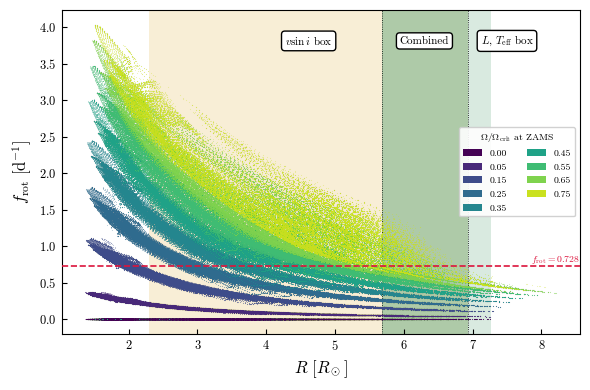

vsini box     R = 2.30 - 6.94 Rsun
L, Teff box   R = 5.68 - 7.27 Rsun
intersection  R = 5.68 - 6.94 Rsun

36,616 MS modes in the allowed radius range; f_rot there spans 0.000 - 1.505 d^-1


In [25]:
# ==========================================================================
# surface rotation vs radius, coloured by initial omega/omega_crit
# ==========================================================================
# The L and Teff boxes translate into a radius range via Stefan-Boltzmann
# (R = sqrt(L) * (Tsun/Teff)^2), so they can be drawn on this axis. The
# vsini box is an independent constraint; only their INTERSECTION is allowed.
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

allm = hd.attach_models(modes, MODELS_PARQUET)
ms = allm[allm["phase"] == "MS"]

# radius implied by the spectroscopic boxes
R_SB_lo = np.sqrt(L_BOX[0]) * (5772.0 / TEFF_BOX[1]) ** 2
R_SB_hi = np.sqrt(L_BOX[1]) * (5772.0 / TEFF_BOX[0]) ** 2
R_vs_lo, R_vs_hi = (R_BOX if R_BOX else (np.nan, np.nan))
R_ok = (max(R_SB_lo, R_vs_lo), min(R_SB_hi, R_vs_hi))   # the intersection

fig, ax = plt.subplots(figsize=(6, 4))

ax.axvspan(R_vs_lo, R_vs_hi, color="goldenrod", alpha=0.18, lw=0, zorder=0)
ax.axvspan(R_SB_lo, R_SB_hi, color="seagreen", alpha=0.18, lw=0, zorder=0)
ax.axvspan(*R_ok, color="seagreen", alpha=0.22, lw=0, zorder=1)
for x in R_ok:
    ax.axvline(x, color="k", lw=0.6, ls=":", zorder=2)

omegas = np.sort(ms["omega"].unique())
colors = plt.cm.viridis(np.linspace(0, 0.92, len(omegas)))
for om, c in zip(omegas, colors):
    s = ms[ms["omega"] == om]
    ax.scatter(s["R"], s["f_rot_model_cpd"], s=0.6, alpha=0.35, color=c,
               lw=0, rasterized=True, zorder=3)

ax.axhline(F_ROT_CPD, color="crimson", lw=1.2, ls="--", zorder=4)
ax.text(ax.get_xlim()[1], F_ROT_CPD, f" $f_{{\\rm rot}}={F_ROT_CPD:.3f}$",
        color="crimson", fontsize=7, ha="right", va="bottom")

y = ax.get_ylim()[1]
ax.text(7.5, y * 0.90, r"$L$, $T_{\rm eff}$ box",
            bbox = dict(facecolor='white',boxstyle='round'),
            horizontalalignment='center', 
            verticalalignment='center',
            fontsize=8)
ax.text((R_vs_lo + R_vs_hi) / 2, y * 0.90, r"$v\sin i$ box",
            bbox = dict(facecolor='white',boxstyle='round'),
            horizontalalignment='center', 
            verticalalignment='center',
            fontsize=8)
ax.text(6.3, y * 0.90, r"Combined",
            bbox = dict(facecolor='white',boxstyle='round'),
            horizontalalignment='center', 
            verticalalignment='center',
            fontsize=8)

# discrete legend: a colourbar would imply omega is continuous, it is not
ax.legend(handles=[Patch(facecolor=c, label=f"{om:.2f}")
                   for om, c in zip(omegas, colors)],
          title=r"$\Omega/\Omega_{\rm crit}$ at ZAMS", fontsize=7,
          title_fontsize=7, loc="center right", ncol=2, framealpha=0.9)

ax.set_xlabel(r"$R\ [R_\odot]$", fontsize=12)
ax.set_ylabel(r"$f_{\rm rot}\ [\rm d^{-1}]$", fontsize=12)
ax.tick_params(labelsize=9)
plt.tight_layout()
for ext in ("pdf", "png"):
    plt.savefig(f"frot_vs_radius.{ext}", bbox_inches="tight", pad_inches=0.01)
plt.show()

print(f"vsini box     R = {R_vs_lo:.2f} - {R_vs_hi:.2f} Rsun")
print(f"L, Teff box   R = {R_SB_lo:.2f} - {R_SB_hi:.2f} Rsun")
print(f"intersection  R = {R_ok[0]:.2f} - {R_ok[1]:.2f} Rsun")
inbox = ms[ms["R"].between(*R_ok)]
print(f"\n{len(inbox):,} MS modes in the allowed radius range; "
      f"f_rot there spans {inbox['f_rot_model_cpd'].min():.3f} - "
      f"{inbox['f_rot_model_cpd'].max():.3f} d^-1")

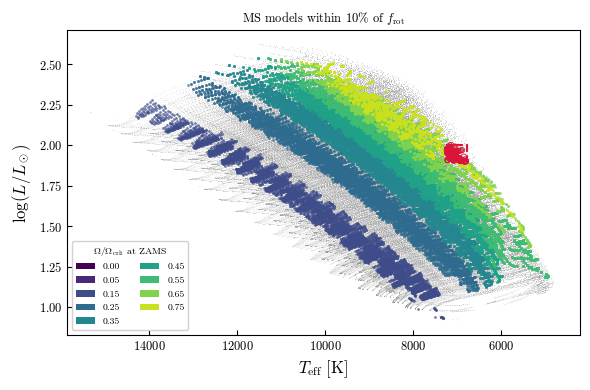

rotation tolerance      : 10.0%
MS modes matching f_rot : 45,380
  ...also inside the L, Teff box: 217

where they live:
         n  M_lo  M_hi      R_lo      R_hi     Xc_lo     Xc_hi
omega                                                         
0.65   133   2.2   2.7  5.765388  6.795657  0.000931  0.183298
0.75    84   2.4   2.6  5.970576  6.657386  0.000864  0.155328


In [26]:
# ==========================================================================
# HRD of the models that reach the observed rotation rate
# ==========================================================================
# Same colour coding. The box is the spectroscopic constraint; anything
# inside it satisfies rotation AND Teff AND L simultaneously.

ROT_TOL = 0.10

rot_ok = ms[(ms["f_rot_model_cpd"] / F_ROT_CPD - 1.0).abs() < ROT_TOL].copy()
rot_ok["logL"] = np.log10(rot_ok["L"])

fig, ax = plt.subplots(figsize=(6, 4))

# faint background: every MS model, for context
ax.scatter(allm.loc[allm.phase == "MS", "Teff"],
           np.log10(allm.loc[allm.phase == "MS", "L"]),
           s=0.4, alpha=0.06, color="0.6", lw=0, rasterized=True, zorder=0)

for om, c in zip(omegas, colors):
    s = rot_ok[rot_ok["omega"] == om]
    if len(s):
        ax.scatter(s["Teff"], s["logL"], s=4, alpha=0.7, color=c, lw=0,
                   rasterized=True, zorder=3)

ax.add_patch(Rectangle(
    (TEFF_BOX[0], np.log10(L_BOX[0])),
    TEFF_BOX[1] - TEFF_BOX[0],
    np.log10(L_BOX[1]) - np.log10(L_BOX[0]),
    fill=False, edgecolor="crimson", lw=1.5, ls="--", zorder=5))

inside = rot_ok[rot_ok["Teff"].between(*TEFF_BOX)
                & rot_ok["L"].between(*L_BOX)]
ax.scatter(inside["Teff"], inside["logL"], s=14, facecolor="none",
           edgecolor="crimson", lw=0.6, zorder=6)

ax.invert_xaxis()
ax.set_xlabel(r"$T_{\rm eff}\ [\rm K]$", fontsize=12)
ax.set_ylabel(r"$\log (L/L_\odot)$", fontsize=12)
ax.tick_params(labelsize=9)
ax.legend(handles=[Patch(facecolor=c, label=f"{om:.2f}")
                   for om, c in zip(omegas, colors)],
          title=r"$\Omega/\Omega_{\rm crit}$ at ZAMS", fontsize=7,
          title_fontsize=7, loc="lower left", ncol=2, framealpha=0.9)
ax.set_title(rf"MS models within {ROT_TOL:.0%} of $f_{{\rm rot}}$", fontsize=9)
plt.tight_layout()
for ext in ("pdf", "png"):
    plt.savefig(f"hrd_rotation_matched.{ext}", bbox_inches="tight",
                pad_inches=0.01)
plt.show()

print(f"rotation tolerance      : {ROT_TOL:.1%}")
print(f"MS modes matching f_rot : {len(rot_ok):,}")
print(f"  ...also inside the L, Teff box: {len(inside):,}")
if len(inside):
    print("\nwhere they live:")
    print(inside.groupby("omega", observed=True)
          .agg(n=("L", "size"), M_lo=("star_mass", "min"),
               M_hi=("star_mass", "max"), R_lo=("R", "min"),
               R_hi=("R", "max"), Xc_lo=("Xc", "min"), Xc_hi=("Xc", "max"))
          .to_string())

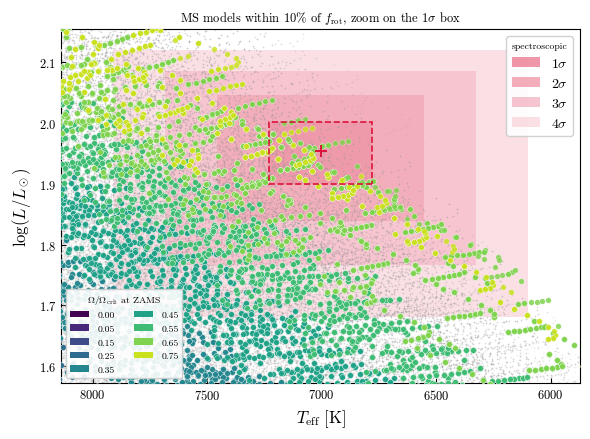

Teff = 7004 +/- 226 K
L    = 89.987 +/- 10.526 L_sun (11.7%, 0.0480 dex)
rotation-matched MS models: 45,380

1 sigma:    217 in both  (Teff alone 3,124, L alone 4,954)
         n  M_lo  M_hi      R_lo      R_hi     Xc_lo     Xc_hi
omega                                                         
0.65   133   2.2   2.7  5.765388  6.795657  0.000931  0.183298
0.75    84   2.4   2.6  5.970576  6.657386  0.000864  0.155328 

2 sigma:    865 in both  (Teff alone 6,325, L alone 9,884)
         n  M_lo  M_hi      R_lo      R_hi     Xc_lo     Xc_hi
omega                                                         
0.55    63   2.4   2.6  5.056218  5.458439  0.000914  0.162574
0.65   558   2.1   2.8  5.047508  6.795657  0.000833  0.183884
0.75   244   2.4   2.6  5.807456  6.657386  0.000864  0.155328 

3 sigma:  2,400 in both  (Teff alone 9,464, L alone 14,910)
          n  M_lo  M_hi      R_lo      R_hi     Xc_lo     Xc_hi
omega                                                          
0.45     86   

In [27]:
# ==========================================================================
# HRD, zoomed on the spectroscopic box, with 1/2/3 sigma bands
# ==========================================================================

ROT_TOL   = 0.1 #F_ROT_TOL_FRAC if F_ROT_TOL_FRAC is not None else 0.10
BOX_COLOR = "crimson"       # band colour; change if it clashes with omegas
PAD_SIG   = 5             # axis limits, in sigma

rot_ok = ms[(ms["f_rot_model_cpd"] / F_ROT_CPD - 1.0).abs() < ROT_TOL].copy()
rot_ok["logL"] = np.log10(rot_ok["L"])

def _box(n):
    """(Teff_lo, Teff_hi, logL_lo, logL_hi) for an n-sigma box."""
    return (TEFF_CENTRAL - n * TEFF_SIGMA, TEFF_CENTRAL + n * TEFF_SIGMA,
            np.log10(L_CENTRAL - n * L_SIGMA),
            np.log10(L_CENTRAL + n * L_SIGMA))

fig, ax = plt.subplots(figsize=(6, 4.5))

# --- sigma bands, drawn widest first. Alphas compound where they overlap,
#     which is what gives the nested darkening (0.13 / 0.24 / 0.34 effective).
for n in (4, 3, 2, 1):
    t_lo, t_hi, l_lo, l_hi = _box(n)
    ax.add_patch(Rectangle((t_lo, l_lo), t_hi - t_lo, l_hi - l_lo,
                           facecolor=BOX_COLOR, alpha=0.13, lw=0, zorder=1))

# the box that is actually applied as a cut
ax.add_patch(Rectangle((TEFF_BOX[0], np.log10(L_BOX[0])),
                       TEFF_BOX[1] - TEFF_BOX[0],
                       np.log10(L_BOX[1]) - np.log10(L_BOX[0]),
                       fill=False, edgecolor=BOX_COLOR, lw=1.2, ls="--",
                       zorder=5))
ax.plot(TEFF_CENTRAL, np.log10(L_CENTRAL), marker="+", ms=9, mew=1.4,
        color=BOX_COLOR, zorder=6)

# --- faint background: every MS model in the field of view
bg = allm[allm.phase == "MS"]
ax.scatter(bg["Teff"], np.log10(bg["L"]), s=1.5, alpha=0.10, color="0.6",
           lw=0, rasterized=True, zorder=2)

# --- rotation-matched models, coloured by ZAMS omega
for om, c in zip(omegas, colors):
    s = rot_ok[rot_ok["omega"] == om]
    if len(s):
        ax.scatter(s["Teff"], s["logL"], s=16, alpha=0.85, color=c,
                   lw=0.2, edgecolor="w", rasterized=True, zorder=4)

t_lo, t_hi, l_lo, l_hi = _box(PAD_SIG)
ax.set_xlim(t_hi, t_lo)                 # inverted, no invert_xaxis() needed
ax.set_ylim(l_lo, l_hi)

ax.set_xlabel(r"$T_{\rm eff}\ [\rm K]$", fontsize=12)
ax.set_ylabel(r"$\log (L/L_\odot)$", fontsize=12)
ax.tick_params(labelsize=9)

leg_sig = ax.legend(
    handles=[Patch(facecolor=BOX_COLOR, alpha=a, label=lab)
             for a, lab in ((0.44, r"$1\sigma$"), (0.34, r"$2\sigma$"),
                            (0.24, r"$3\sigma$"), (0.13, r"$4\sigma$"))],
    fontsize=10, loc="upper right", framealpha=0.9,
    title="spectroscopic", title_fontsize=7)
ax.add_artist(leg_sig)
ax.legend(handles=[Patch(facecolor=c, label=f"{om:.2f}")
                   for om, c in zip(omegas, colors)],
          title=r"$\Omega/\Omega_{\rm crit}$ at ZAMS", fontsize=7,
          title_fontsize=7, loc="lower left", ncol=2, framealpha=0.9)
ax.set_title(rf"MS models within {ROT_TOL:.0%} of $f_{{\rm rot}}$, "
             rf"zoom on the {TEFF_NSIGMA:.0f}$\sigma$ box", fontsize=9)

plt.tight_layout()
for ext in ("pdf", "png"):
    plt.savefig(f"hrd_rotation_matched_zoom.{ext}", bbox_inches="tight",
                pad_inches=0.01)
plt.show()

# --- how many survive at each sigma level
print(f"Teff = {TEFF_CENTRAL:.0f} +/- {TEFF_SIGMA:.0f} K")
print(f"L    = {L_CENTRAL:.3f} +/- {L_SIGMA:.3f} L_sun "
      f"({L_SIGMA/L_CENTRAL:.1%}, {np.log10(1+L_SIGMA/L_CENTRAL):.4f} dex)")
print(f"rotation-matched MS models: {len(rot_ok):,}\n")
for n in (1, 2, 3):
    t_lo, t_hi, _, _ = _box(n)
    m = (rot_ok["Teff"].between(t_lo, t_hi)
         & rot_ok["L"].between(L_CENTRAL - n*L_SIGMA, L_CENTRAL + n*L_SIGMA))
    n_t = rot_ok["Teff"].between(t_lo, t_hi).sum()
    n_l = rot_ok["L"].between(L_CENTRAL - n*L_SIGMA,
                              L_CENTRAL + n*L_SIGMA).sum()
    print(f"{n} sigma: {m.sum():6,} in both  "
          f"(Teff alone {n_t:,}, L alone {n_l:,})")
    if m.sum():
        print(rot_ok[m].groupby("omega", observed=True)
              .agg(n=("L", "size"), M_lo=("star_mass", "min"),
                   M_hi=("star_mass", "max"), R_lo=("R", "min"),
                   R_hi=("R", "max"), Xc_lo=("Xc", "min"),
                   Xc_hi=("Xc", "max")).to_string(), "\n")

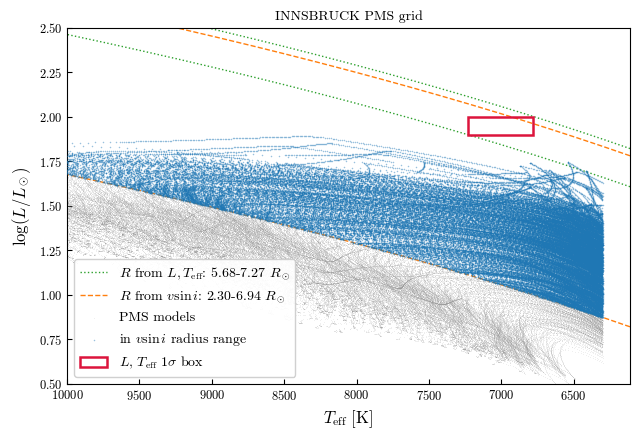

INNSBRUCK PMS grid: 177,741 models
  Teff  6300 - 10300 K      box 6778 - 7231
  L     3.1 - 77.8 Lsun   box 79.5 - 100.5
  R     1.25 - 5.82 Rsun   vsini 2.30 - 6.94
  M     1.26 - 2.50 Msun  (grid ceiling is 2.5 in Steindl et al. 2022)

in Teff box            : 25,348
in L box               : 0
in BOTH (the red box)  : 0
in vsini radius range  : 78,446
in box AND radius      : 0

*** NO INNSBRUCK PMS MODEL REACHES THE BOX ***
    the box needs R >= 5.68 Rsun at these temperatures;
    the grid reaches 5.82 Rsun and stops at 2.50 Msun.
    This is a result, not a bug: an accreting-protostar PMS grid
    capped at 2.5 Msun cannot make a star this luminous at this
    temperature. Report it as an exclusion of the PMS hypothesis
    within this grid's parameter space.


In [28]:
SOURCE_LABEL = "INNSBRUCK"
if SOURCE_LABEL=="INNSBRUCK":
    inn_models = pd.read_parquet(INN_MODELS_PARQUET)
    pms = inn_models[inn_models["phase"] == "PMS"].copy()
else:
    models = pd.read_parquet(MODELS_ALL_PARQUET)
    pms = models[models["phase"] == "PMS"].copy()

pms["logL"] = np.log10(pms["L"])
 
# radius ranges
R_SB = (np.sqrt(L_BOX[0]) * (5772.0 / TEFF_BOX[1]) ** 2,
        np.sqrt(L_BOX[1]) * (5772.0 / TEFF_BOX[0]) ** 2)
f_hz = F_ROT_CPD / 86400.0
R_VS = tuple(sorted(
    (VSINI_KMS + s * VSINI_ERR_KMS) * 1e3
    / (2 * np.pi * f_hz * np.sin(np.radians(INCL_VLTI_DEG - s * INCL_ERR_DEG)))
    / hd.R_SUN for s in (-1, +1)))
 
in_box = pms["Teff"].between(*TEFF_BOX) & pms["L"].between(*L_BOX)
in_vs = pms["R"].between(*R_VS)
 
fig, ax = plt.subplots(figsize=(6.5, 4.5))
 
# constant-radius lines: logL = 2*log10(R) + 4*log10(Teff/Tsun)
tt = np.linspace(pms["Teff"].min() * 0.97, pms["Teff"].max() * 1.03, 200)
iso = lambda R: 2 * np.log10(R) + 4 * np.log10(tt / 5772.0)
for R, ls, c, lab in ((R_SB[0], ":", "tab:green", None), (R_SB[1], ":", "tab:green", None),
                      (R_VS[0], "--", "tab:orange", None),
                      (R_VS[1], "--", "tab:orange", None)):
    ax.plot(tt, iso(R), ls=ls, color=c, lw=1, zorder=1)
ax.plot([], [], ":", color="tab:green", lw=1,
        label=rf"$R$ from $L,T_{{\rm eff}}$: {R_SB[0]:.2f}-{R_SB[1]:.2f} $R_\odot$")
ax.plot([], [], "--", color="tab:orange", lw=1,
        label=rf"$R$ from $v\sin i$: {R_VS[0]:.2f}-{R_VS[1]:.2f} $R_\odot$")
 
ax.scatter(pms.loc[~in_vs, "Teff"], pms.loc[~in_vs, "logL"], s=0.5, alpha=0.10,
           color="0.6", lw=0, rasterized=True, zorder=2, label="PMS models")
ax.scatter(pms.loc[in_vs, "Teff"], pms.loc[in_vs, "logL"], s=1.2, alpha=0.45,
           color="tab:blue", lw=0, rasterized=True, zorder=3,
           label=r"in $v\sin i$ radius range")
 
ax.add_patch(Rectangle((TEFF_BOX[0], np.log10(L_BOX[0])),
                       TEFF_BOX[1] - TEFF_BOX[0],
                       np.log10(L_BOX[1]) - np.log10(L_BOX[0]),
                       fill=False, edgecolor="crimson", lw=1.8, ls="-",
                       zorder=6, label=r"$L$, $T_{\rm eff}$ $1\sigma$ box"))
# if in_box.any():
#     both = in_box & in_vs
#     ax.scatter(pms.loc[both, "Teff"], pms.loc[both, "logL"], s=18,
#                facecolor="none", edgecolor="crimson", lw=0.8, zorder=7,
#                label="satisfies both")
ax.set_xlim(pms["Teff"].min()*0.97, 10000)
ax.set_ylim(0.5, 2.5)
ax.invert_xaxis()
ax.set_xlabel(r"$T_{\rm eff}\ [\rm K]$", fontsize=12)
ax.set_ylabel(r"$\log (L/L_\odot)$", fontsize=12)
ax.tick_params(labelsize=9)
ax.legend(fontsize=10, loc="lower left", framealpha=0.92)
ax.set_title(f"{SOURCE_LABEL} PMS grid", fontsize=10)
plt.tight_layout()
for ext in ("pdf", "png"):
    plt.savefig(f"hrd_{SOURCE_LABEL.lower()}_pms.{ext}",
                bbox_inches="tight", pad_inches=0.01)
plt.show()
 
# --- does the grid even reach the box? ------------------------------------
print(f"{SOURCE_LABEL} PMS grid: {len(pms):,} models")
print(f"  Teff  {pms.Teff.min():.0f} - {pms.Teff.max():.0f} K"
      f"      box {TEFF_BOX[0]:.0f} - {TEFF_BOX[1]:.0f}")
print(f"  L     {pms.L.min():.1f} - {pms.L.max():.1f} Lsun"
      f"   box {L_BOX[0]:.1f} - {L_BOX[1]:.1f}")
print(f"  R     {pms.R.min():.2f} - {pms.R.max():.2f} Rsun"
      f"   vsini {R_VS[0]:.2f} - {R_VS[1]:.2f}")
print(f"  M     {pms.M.min():.2f} - {pms.M.max():.2f} Msun  "
      "(grid ceiling is 2.5 in Steindl et al. 2022)")
 
print(f"\nin Teff box            : {pms['Teff'].between(*TEFF_BOX).sum():,}")
print(f"in L box               : {pms['L'].between(*L_BOX).sum():,}")
print(f"in BOTH (the red box)  : {in_box.sum():,}")
print(f"in vsini radius range  : {in_vs.sum():,}")
print(f"in box AND radius      : {(in_box & in_vs).sum():,}")
 
if in_box.sum() == 0:
    # A grid that cannot reach the observed luminosity at the observed
    # temperature excludes itself, regardless of any seismic argument.
    need_R = np.sqrt(L_BOX[0]) * (5772.0 / TEFF_BOX[1]) ** 2
    print(f"\n*** NO {SOURCE_LABEL} PMS MODEL REACHES THE BOX ***")
    print(f"    the box needs R >= {need_R:.2f} Rsun at these temperatures;")
    print(f"    the grid reaches {pms.R.max():.2f} Rsun and stops at "
          f"{pms.M.max():.2f} Msun.")
    print("    This is a result, not a bug: an accreting-protostar PMS grid")
    print("    capped at 2.5 Msun cannot make a star this luminous at this")
    print("    temperature. Report it as an exclusion of the PMS hypothesis")
    print("    within this grid's parameter space.")
else:
    print("\nwhere the surviving models sit:")
    print(pms[in_box].agg({"M": ["min", "max"], "age_Myr": ["min", "max"],
                           "R": ["min", "max"], "Teff": ["min", "max"],
                           "L": ["min", "max"]}).to_string())

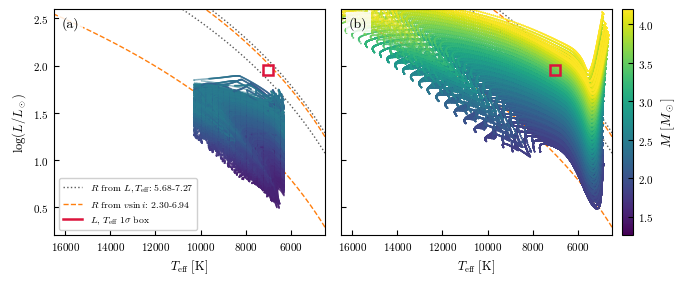

grid           models         M range    L max   R max   in box   +vsini
Innsbruck     177,741    1.26-2.50        77.8    5.82        0        0
IvS         1,010,512    1.80-4.20       562.2   26.44    1,470    1,420

Innsbruck: NO models in the box (mass ceiling 2.50 Msun, L max 77.8 Lsun)

IvS models in the box:
  M       3.10 - 3.80 Msun
  age     0.69 - 1.45 Myr
  R       5.78 - 7.22 Rsun
  tracks  235


In [29]:
# ==========================================================================
# Innsbruck vs IvS PMS grids, side by side, coloured by mass
# ==========================================================================
# Shared axes, shared colour normalisation and a single colourbar, so the two
# panels are directly comparable. A per-panel colour scale would make the
# grids look alike when their mass ranges differ (Innsbruck stops at 2.5
# Msun, IvS runs to 3.2), which is one of the things this plot should reveal.
from matplotlib.cm import ScalarMappable

PANELS = [
    ("Innsbruck", INN_MODELS_PARQUET),
    ("IvS",       MODELS_ALL_PARQUET),      # or "models.parquet"
]
CMAP = "viridis"

XLIM = (16500, 4500)     # Teff, descending -- axis is inverted
YLIM = (0.2, 2.6)       # log L/Lsun

grids = {}
for lab, path in PANELS:
    d = pd.read_parquet(path)
    d = d[d["phase"] == "PMS"].copy()
    d["logL"] = np.log10(d["L"])
    grids[lab] = d

# one normalisation across both panels
mall = np.concatenate([d["M"].to_numpy() for d in grids.values()])
norm = Normalize(vmin=mall.min(), vmax=mall.max())

# radius constraints (same in both panels)
R_SB = (np.sqrt(L_BOX[0]) * (5772.0 / TEFF_BOX[1]) ** 2,
        np.sqrt(L_BOX[1]) * (5772.0 / TEFF_BOX[0]) ** 2)
f_hz = F_ROT_CPD / 86400.0
R_VS = tuple(sorted(
    (VSINI_KMS + s * VSINI_ERR_KMS) * 1e3
    / (2 * np.pi * f_hz * np.sin(np.radians(INCL_VLTI_DEG - s * INCL_ERR_DEG)))
    / hd.R_SUN for s in (-1, +1)))

fig, axes = plt.subplots(1, 2, figsize=(17.6/2.54, 7.0/2.54), sharex=True, sharey=True)

tlo = min(d["Teff"].min() for d in grids.values()) * 0.97
thi = max(d["Teff"].max() for d in grids.values()) * 1.03
tt = np.linspace(tlo, thi, 200)
iso = lambda R: 2 * np.log10(R) + 4 * np.log10(tt / 5772.0)

for i, (ax, (lab, _)) in enumerate(zip(axes, PANELS)):
    d = grids[lab]

    for R in R_SB:
        ax.plot(tt, iso(R), ":", color="0.35", lw=1, zorder=1)
    for R in R_VS:
        ax.plot(tt, iso(R), "--", color="tab:orange", lw=1, zorder=1)

    ax.scatter(d["Teff"], d["logL"], c=d["M"], cmap=CMAP, norm=norm,
               s=1.5, alpha=0.5, lw=0, rasterized=True, zorder=2)

    ax.add_patch(Rectangle((TEFF_BOX[0], np.log10(L_BOX[0])),
                           TEFF_BOX[1] - TEFF_BOX[0],
                           np.log10(L_BOX[1]) - np.log10(L_BOX[0]),
                           fill=False, edgecolor="crimson", lw=1.8, zorder=6))

    inbox = d["Teff"].between(*TEFF_BOX) & d["L"].between(*L_BOX)
    both = inbox & d["R"].between(*R_VS)
    ax.set_xlabel(r"$T_{\rm eff}\ [\rm K]$", fontsize=9)
    ax.tick_params(labelsize=8)
    ax.text(0.03, 0.97, f"({'ab'[i]})", transform=ax.transAxes,
            va="top", ha="left", fontsize=10, fontweight="bold",
            bbox=dict(boxstyle="square,pad=0.25", fc="white", ec="none",
                      alpha=0.85))

axes[0].set_ylabel(r"$\log (L/L_\odot)$", fontsize=9)
axes[0].set_xlim(*XLIM)
axes[0].set_ylim(*YLIM)

# legend for the line styles only; mass goes on the colourbar
axes[0].plot([], [], ":", color="0.35", lw=1,
             label=rf"$R$ from $L,T_{{\rm eff}}$: {R_SB[0]:.2f}-{R_SB[1]:.2f}")
axes[0].plot([], [], "--", color="tab:orange", lw=1,
             label=rf"$R$ from $v\sin i$: {R_VS[0]:.2f}-{R_VS[1]:.2f}")
axes[0].plot([], [], "-", color="crimson", lw=1.8,
             label=r"$L$, $T_{\rm eff}$ 1$\sigma$ box")
axes[0].legend(fontsize=7, loc="lower left", framealpha=0.92)

fig.subplots_adjust(left=0.075, right=0.88, bottom=0.15, top=0.97,
                    wspace=0.06)
cax = fig.add_axes([0.895, 0.15, 0.016, 0.82])
cb = fig.colorbar(ScalarMappable(norm=norm, cmap=CMAP), cax=cax)
cb.set_label(r"$M\ [M_\odot]$", fontsize=10)
cb.ax.tick_params(labelsize=8)

for ext in ("pdf", "png"):
    plt.savefig(f"hrd_pms_grids_by_mass.{ext}",
                pad_inches=0.02)
plt.show()

# --- comparison ----------------------------------------------------------
print(f"{'grid':<12}{'models':>9}{'M range':>16}{'L max':>9}{'R max':>8}"
      f"{'in box':>9}{'+vsini':>9}")
for lab, _ in PANELS:
    d = grids[lab]
    inbox = d["Teff"].between(*TEFF_BOX) & d["L"].between(*L_BOX)
    both = inbox & d["R"].between(*R_VS)
    print(f"{lab:<12}{len(d):>9,}{d['M'].min():>8.2f}-{d['M'].max():<7.2f}"
          f"{d['L'].max():>9.1f}{d['R'].max():>8.2f}"
          f"{inbox.sum():>9,}{both.sum():>9,}")

# The mass at which each grid enters the box is the number to compare: if the
# two disagree, it is a statement about the input physics, not about the
# seismology. If one grid never enters, check whether its mass ceiling is the
# reason before calling it an exclusion.
for lab, _ in PANELS:
    d = grids[lab]
    inbox = d["Teff"].between(*TEFF_BOX) & d["L"].between(*L_BOX)
    if inbox.any():
        s = d[inbox]
        print(f"\n{lab} models in the box:")
        print(f"  M       {s['M'].min():.2f} - {s['M'].max():.2f} Msun")
        print(f"  age     {s['age_Myr'].min():.2f} - {s['age_Myr'].max():.2f} Myr")
        print(f"  R       {s['R'].min():.2f} - {s['R'].max():.2f} Rsun")
        print(f"  tracks  {s['track_id'].nunique()}")
    else:
        print(f"\n{lab}: NO models in the box "
              f"(mass ceiling {d['M'].max():.2f} Msun, "
              f"L max {d['L'].max():.1f} Lsun)")

(d) M2.5_Z0.014_omega0.65_fov0.025 profile 359, Xc=0.0100, R=5.56
late PMS: Xc 0.6869 - 0.7251, 10 tracks
late MS: Xc 0.0009 - 0.0010, 10 tracks


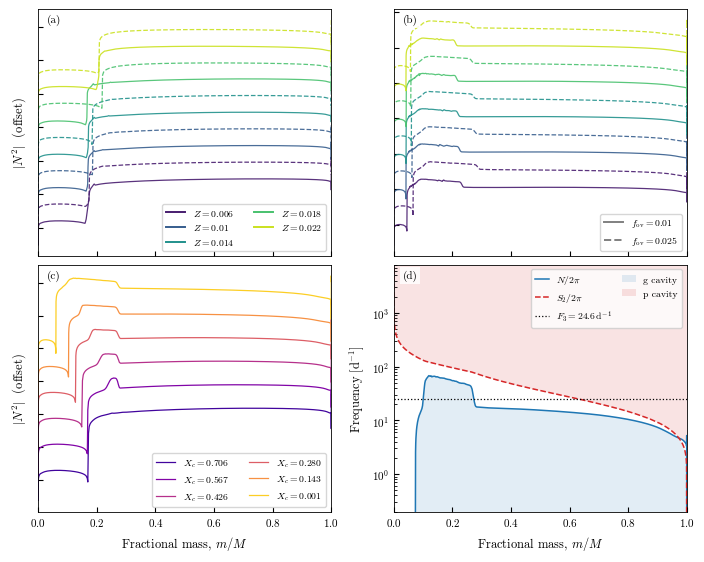

In [36]:
# ==========================================================================
# APPENDIX: N^2 and S_l^2 SHAPE ACROSS Z AND f_ov, AT FIXED M AND omega
# ==========================================================================
# Offset vertically by construction -- this compares the SHAPE of the
# cavities, not their values, so the y axis is arbitrary and unlabelled in
# value. Curves are |N^2| and S_l^2 in rad^2/s^2, each model multiplied by
# 10^(OFFSET_DEC * j) to separate it from the one below.
from matplotlib.lines import Line2D

GRID_ROOT   = Path("/STER/kianTedeskino/HD35929/mesa_grid/grid_runs")
LOGS_SUBDIR = "LOGS"

M_FIX, OMEGA_FIX = 2.5, 0.65
Z_LIST   = [0.006, 0.010, 0.014, 0.018, 0.022]
FOV_LIST = [0.010, 0.025]
L_DEG      = P_L
OFFSET_DEC = 3.0                      # decades between successive models
RSUN_CM    = 6.957e10

CM_ = 1/2.54
Z_COLORS   = dict(zip(Z_LIST, plt.cm.viridis(np.linspace(0.08, 0.92, len(Z_LIST)))))
FOV_STYLES = {0.010: "-", 0.025: "--"}

EVO_TRACK = "M2.5_Z0.014_omega0.65_fov0.025"   # StORM best MS track
EVO_N      = 6                                   # epochs in panel (c)
PROP_XC   = 0.0100                              # StORM best model's Xc
SEC_DAY    = 86400.0

FIG_RC = {"font.size": 8, "axes.labelsize": 9,
          "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 7.5,
          "axes.linewidth": 0.6, "xtick.top": False, "ytick.right": False,
          "xtick.direction": "in", "ytick.direction": "in"}

_MODS = _MODS_ALL if "_MODS_ALL" in dir() else pd.read_parquet(MODELS_ALL_PARQUET)
_WANT = ("mass", "radius", "logR", "brunt_N2", "csound",
         "gamma1", "logP", "logRho")


def _read_struct(path):
    with open(path) as fh:
        for _ in range(5):
            fh.readline()
        header = fh.readline().split()
    have = [c for c in _WANT if c in header]
    return pd.read_csv(path, sep=r"\s+", skiprows=5, header=0, usecols=have)


def _cavities(p, l=L_DEG):
    """m/M (surface->centre as MESA writes it), |N^2| and S_l^2, rad^2/s^2."""
    x = p["mass"].to_numpy() / p["mass"].to_numpy()[0]
    N2 = np.abs(p["brunt_N2"].to_numpy())
    if "csound" in p:
        cs = p["csound"].to_numpy()
    elif {"gamma1", "logP", "logRho"} <= set(p.columns):
        cs = np.sqrt(p.gamma1.to_numpy() * 10**p.logP.to_numpy()
                     / 10**p.logRho.to_numpy())
    else:
        return x, N2, None
    r = (p["radius"].to_numpy() if "radius" in p
         else 10**p["logR"].to_numpy()) * RSUN_CM
    with np.errstate(divide="ignore", invalid="ignore"):
        S2 = l*(l+1.0) * cs**2 / r**2
    return x, N2, S2


def _epoch_profiles(track):
    """(late PMS, late MS) profile numbers from the parquet, not an index file."""
    m = _MODS[_MODS.track_id.astype(str) == track]
    out = []
    for ph in ("PMS", "MS"):
        s = m[m.phase == ph]
        out.append((int(s.loc[s.age_Myr.idxmax(), "profile"]),
                    float(s.loc[s.age_Myr.idxmax(), "Xc"])) if len(s) else None)
    return out

FIG_RC = {"font.size": 8, "axes.labelsize": 9,
          "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 7,
          "axes.linewidth": 0.6, "xtick.top": False, "ytick.right": False,
          "xtick.direction": "in", "ytick.direction": "in"}

with plt.rc_context(FIG_RC):
    fig, axes = plt.subplots(2, 2, figsize=(17.6*CM_, 14.0*CM_),
                             sharex=True, layout="constrained")
    PANEL = [["(a)", "(b)"], ["(c)", "(d)"]]
    j, missing, xc_seen = 0, [], {0: [], 1: []}

    for Z in Z_LIST:
        for fov in FOV_LIST:
            track = f"M{M_FIX:.1f}_Z{Z:.3f}_omega{OMEGA_FIX:.2f}_fov{fov:.3f}"
            logs  = GRID_ROOT / track / LOGS_SUBDIR
            eps   = _epoch_profiles(track)
            if not logs.exists() or all(e is None for e in eps):
                missing.append(track); continue
            off = 10.0 ** (OFFSET_DEC * j)
            for col, e in enumerate(eps):
                if e is None:
                    continue
                pnum, xc = e
                f = logs / f"profile{pnum}.data"
                if not f.exists():
                    missing.append(f.name); continue
                x, N2, S2 = _cavities(_read_struct(f))
                xc_seen[col].append(xc)
                kw = dict(color=Z_COLORS[Z], ls=FOV_STYLES[fov],
                          lw=0.9, alpha=0.9)
                axes[0, col].semilogy(x, N2 * off, **kw)
            j += 1

    axes[0, 0].set_ylabel(r"$|N^2|$  (offset)")
    axes[1, 0].set_ylabel(rf"$S_{{{L_DEG}}}^2$  (offset)")
    for col in (0, 1):
        axes[1, col].set_xlabel(r"Fractional mass, $m/M$")
    for ax_ in (axes[0, 0], axes[0, 1], axes[1, 0]):
        ax_.set_yticklabels([])
    for row in (0, 1):
        for col in (0, 1):
            axes[row, col].text(0.03, 0.98, PANEL[row][col],
                                transform=axes[row, col].transAxes,
                                va="top", fontweight="bold",
                                bbox=dict(boxstyle="square,pad=0.25",
                                          fc="white", ec="none", alpha=0.85))

    axes[0, 0].legend(
        handles=[Line2D([0], [0], color=c, lw=1.4, label=f"$Z={Z}$")
                 for Z, c in Z_COLORS.items()],
        ncol=2, frameon=True, loc="lower right")
    axes[0, 1].legend(
        handles=[Line2D([0], [0], color="grey", ls=ls, lw=1.4,
                        label=rf"$f_{{\rm ov}}={fov}$")
                 for fov, ls in FOV_STYLES.items()],
        ncol=1, frameon=True, loc="lower right")

    # --- (c) one track through its evolution ---------------------------
    ms = _MODS[(_MODS.track_id.astype(str) == EVO_TRACK)
               & (_MODS.phase == "MS")]
    targets = np.linspace(ms.Xc.max(), ms.Xc.min(), EVO_N)
    evo = plt.cm.plasma(np.linspace(0.1, 0.9, EVO_N))
    for k, t in enumerate(targets):
        r = ms.iloc[(ms.Xc - t).abs().argsort().iloc[0]]
        f = GRID_ROOT / EVO_TRACK / LOGS_SUBDIR / f"profile{int(r.profile)}.data"
        if not f.exists():
            continue
        x, N2, _ = _cavities(_read_struct(f))
        axes[1, 0].semilogy(x, N2 * 10.0**(OFFSET_DEC * k), lw=0.9,
                            color=evo[k], label=rf"$X_c={r.Xc:.3f}$")
    axes[1, 0].set_yticklabels([])
    axes[1, 0].set_ylabel(r"$|N^2|$  (offset)")
    axes[1, 0].legend(ncol=2, frameon=True, loc="lower right")

    # --- (d) propagation diagram, ONE profile --------------------------
    # In d^-1 here, not squared: a propagation diagram is only readable
    # against an actual mode frequency, which is the point of the panel.
    r = ms.iloc[(ms.Xc - PROP_XC).abs().argsort().iloc[0]]
    p = _read_struct(GRID_ROOT / EVO_TRACK / LOGS_SUBDIR
                     / f"profile{int(r.profile)}.data")
    x, N2s, S2s = _cavities(p)
    N2raw = p["brunt_N2"].to_numpy()
    N_d = np.where(N2raw > 0, np.sqrt(np.clip(N2raw, 0, None)), 0.0) \
        / (2*np.pi) * SEC_DAY
    S_d = np.sqrt(S2s) / (2*np.pi) * SEC_DAY

    ax = axes[1, 1]
    ylo, yhi = 1e-1, 1e4
    ax.semilogy(x, np.where(N_d > 0, N_d, ylo), color="C0", lw=1.1,
                label=r"$N/2\pi$")
    ax.semilogy(x, S_d, color="C3", lw=1.1, ls="--",
                label=rf"$S_{{{L_DEG}}}/2\pi$")
    ax.fill_between(x, ylo, np.minimum(N_d, S_d), color="C0", alpha=0.13,
                    lw=0, label="g cavity")
    ax.fill_between(x, np.maximum(N_d, S_d), yhi, color="C3", alpha=0.13,
                    lw=0, label="p cavity")
    ax.axhline(24.594737, color="k", ls=":", lw=0.9,
               label=rf"$F_3=24.6\,$d$^{{-1}}$")
    ax.set_ylim(0.2, 8e3)
    ax.set_xlim(0.0, 1.0)
    ax.set_ylabel(r"Frequency $[\mathrm{d}^{-1}]$")
    h, l = ax.get_legend_handles_labels()
    order = [0, 1, 4, 2, 3]        # N, S_l, F_3 | g cavity, p cavity
    ax.legend([h[i] for i in order], [l[i] for i in order],
              ncol=2, frameon=True, loc="upper right",
              columnspacing=1.0, handlelength=1.4)
    print(f"(d) {EVO_TRACK} profile {int(r.profile)}, Xc={r.Xc:.4f}, "
          f"R={r.R:.2f}")

    fig.savefig("cavities_Z_fov.pdf", bbox_inches="tight", pad_inches=0.02)
    fig.savefig("cavities_Z_fov.png", dpi=200, bbox_inches="tight", pad_inches=0.02)


if missing:
    print("missing:", ", ".join(missing))
for col, lab in ((0, "late PMS"), (1, "late MS")):
    if xc_seen[col]:
        print(f"{lab}: Xc {min(xc_seen[col]):.4f} - {max(xc_seen[col]):.4f}, "
              f"{len(xc_seen[col])} tracks")